# 03 · Forecasting the NFT market: regime model and agent-based state-space model

Two forecasting approaches built on a daily NFT market series. **They answer different questions and are evaluated on different data, so their scores must not be compared directly.**

| | Part A: two-state HMM | Part B: Chiarella model + particle filter |
|---|---|---|
| Question | Can bull/bear regimes be **detected and predicted one step ahead**? | Can a calibrated agent-based model **forecast real returns**? |
| Data | **Synthetic** returns simulated from a known HMM (real market signals drive the transitions) | **Real** daily NFT returns |
| Fit | Baum–Welch (EM), 5 restarts | SMM / GMM with differential evolution on rolling 365-day windows |
| Inference | Forward filter, smoother, Viterbi | SIR particle filter on the latent state $(p_t, m_t, v_t)$ |
| Score | Accuracy of the predicted **hidden state** vs. the simulated truth | Directional hit-rate, RMSE and CRPS of 30-day return forecasts |
| Headline | 75.2% state accuracy out of sample (majority-class baseline: 55%) | 47.8% directional hit-rate (coin flip: 50%) |

Part A is a **method validation** (can the estimator recover a structure we planted?). Part B is a **real-data test**, and it finds no directional predictability. That is the expected result for a market whose daily returns have a 50% standard deviation.

*Data and outputs.* The dataset is not redistributed (see `data/README.md`), so this notebook is shown with the outputs of the original team run. Code comments and printed labels were translated to English; figure labels remain as rendered at the time. A few cells of Part B (marked †) were run but their outputs were not saved in the original notebook.

## 0 · From 2.4 M sales to a daily market series

Daily aggregation of all sales: median log-price, volume, quantity and gas price; rows with unparseable timestamps (92,873, i.e. 3.9%) are dropped. The resulting "market" log-return has mean ≈ 0, **standard deviation 0.50**, skewness −0.99 and excess kurtosis 8.3. As discussed in notebook 02, much of this volatility comes from changes in the mix of collections traded each day rather than from price moves.

In [1]:
# ============================================================
# BLOCK 0 — Imports & Data Loading
# ============================================================

import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from scipy.special import logsumexp
import warnings
warnings.filterwarnings("ignore")

# ── Plotting style ──────────────────────────────────────────
plt.rcParams.update({
    "figure.facecolor": "#0f0f0f",
    "axes.facecolor":   "#1a1a1a",
    "axes.edgecolor":   "#444",
    "axes.labelcolor":  "#ddd",
    "xtick.color":      "#aaa",
    "ytick.color":      "#aaa",
    "text.color":       "#eee",
    "grid.color":       "#2a2a2a",
    "grid.linestyle":   "--",
    "axes.grid":        True,
    "font.family":      "monospace",
})

BULL_COLOR = "#00e676"   # green
BEAR_COLOR = "#ff1744"   # red
NEUTRAL_COLOR = "#90caf9" # blue

# ── Load data ───────────────────────────────────────────────
FILE_PATH = "../data/sales.parquet"   # Parquet file
FILE_FORMAT = "parquet"                 # "csv" or "parquet"

if FILE_FORMAT == "parquet":
    df_raw = pl.read_parquet(FILE_PATH)
elif FILE_FORMAT == "csv":
    df_raw = pl.read_csv(FILE_PATH, try_parse_dates=True)
else:
    raise ValueError(f"Unsupported format: {FILE_FORMAT}")

# ── Quick sanity check ───────────────────────────────────────
print("Shape          :", df_raw.shape)
print("Columns        :", df_raw.columns)
print("Dtypes         :\n", df_raw.dtypes)
print("\nNull counts    :\n", df_raw.null_count())
print("\nSample (3 rows):\n", df_raw.head(3))

Shape          : (2382584, 32)
Columns        : ['event_type', 'order_hash', 'chain', 'protocol_address', 'closing_date', 'nft_identifier', 'nft_collection', 'nft_contract', 'nft_token_standard', 'nft_name', 'nft_description', 'nft_image_url', 'nft_display_image_url', 'nft_display_animation_url', 'nft_metadata_url', 'nft_opensea_url', 'nft_updated_at', 'nft_is_disabled', 'nft_is_nsfw', 'quantity', 'seller', 'buyer', 'payment_quantity', 'payment_token_address', 'payment_decimals', 'payment_symbol', 'transaction', 'event_timestamp', 'eth_usd_price', 'avg_gas_price', 'payment_usd_price', 'log_usd_price']
Dtypes         :
 [String, String, String, String, String, Int64, String, String, String, String, String, String, String, String, String, String, String, Boolean, Boolean, Int64, String, String, Float64, String, Int64, String, String, String, Float64, Float64, Float64, Float64]

Null counts    :
 shape: (1, 32)
┌────────────┬────────────┬───────┬────────────┬───┬───────────┬───────────┬──

🔍 CHECK - timestamp format:
Raw value examples:
shape: (5, 1)
┌─────────────────────┐
│ event_timestamp     │
│ ---                 │
│ str                 │
╞═════════════════════╡
│ 2025-04-30 21:30:11 │
│ 2025-04-30 20:45:11 │
│ 2025-04-30 11:37:59 │
│ 2025-04-30 02:58:47 │
│ 2025-04-30 01:02:47 │
└─────────────────────┘

First timestamp : '2025-04-30 21:30:11'
Current dtype : String
Detected format (with space) : %Y-%m-%d %H:%M:%S



📊 Timestamp parsing : 92,873 nulls out of 2,382,584 rows

🧹 Cleaning : 92,873 rows removed
✅ Remaining rows : 2,289,711

📅 Daily series : 1461 days
Period : 2021-05-01 → 2025-04-30

Preview:
shape: (5, 7)
┌────────────┬───────────┬───────────────┬─────────────┬────────┬───────────────┬───────────┐
│ date       ┆ log_price ┆ log_price_std ┆ usd_price   ┆ volume ┆ quantity_sold ┆ gas_price │
│ ---        ┆ ---       ┆ ---           ┆ ---         ┆ ---    ┆ ---           ┆ ---       │
│ date       ┆ f64       ┆ f64           ┆ f64         ┆ u32    ┆ f64           ┆ f64       │
╞════════════╪═══════════╪═══════════════╪═════════════╪════════╪═══════════════╪═══════════╡
│ 2021-05-01 ┆ 6.378729  ┆ 0.659046      ┆ 589.178564  ┆ 1791   ┆ 1791.0        ┆ 59.677505 │
│ 2021-05-02 ┆ 7.189525  ┆ 0.739343      ┆ 1325.473212 ┆ 1663   ┆ 1663.0        ┆ 43.095065 │
│ 2021-05-03 ┆ 8.125519  ┆ 0.928         ┆ 3379.619889 ┆ 1821   ┆ 1821.0        ┆ 66.900439 │
│ 2021-05-04 ┆ 8.898457  ┆ 1.047871      ┆

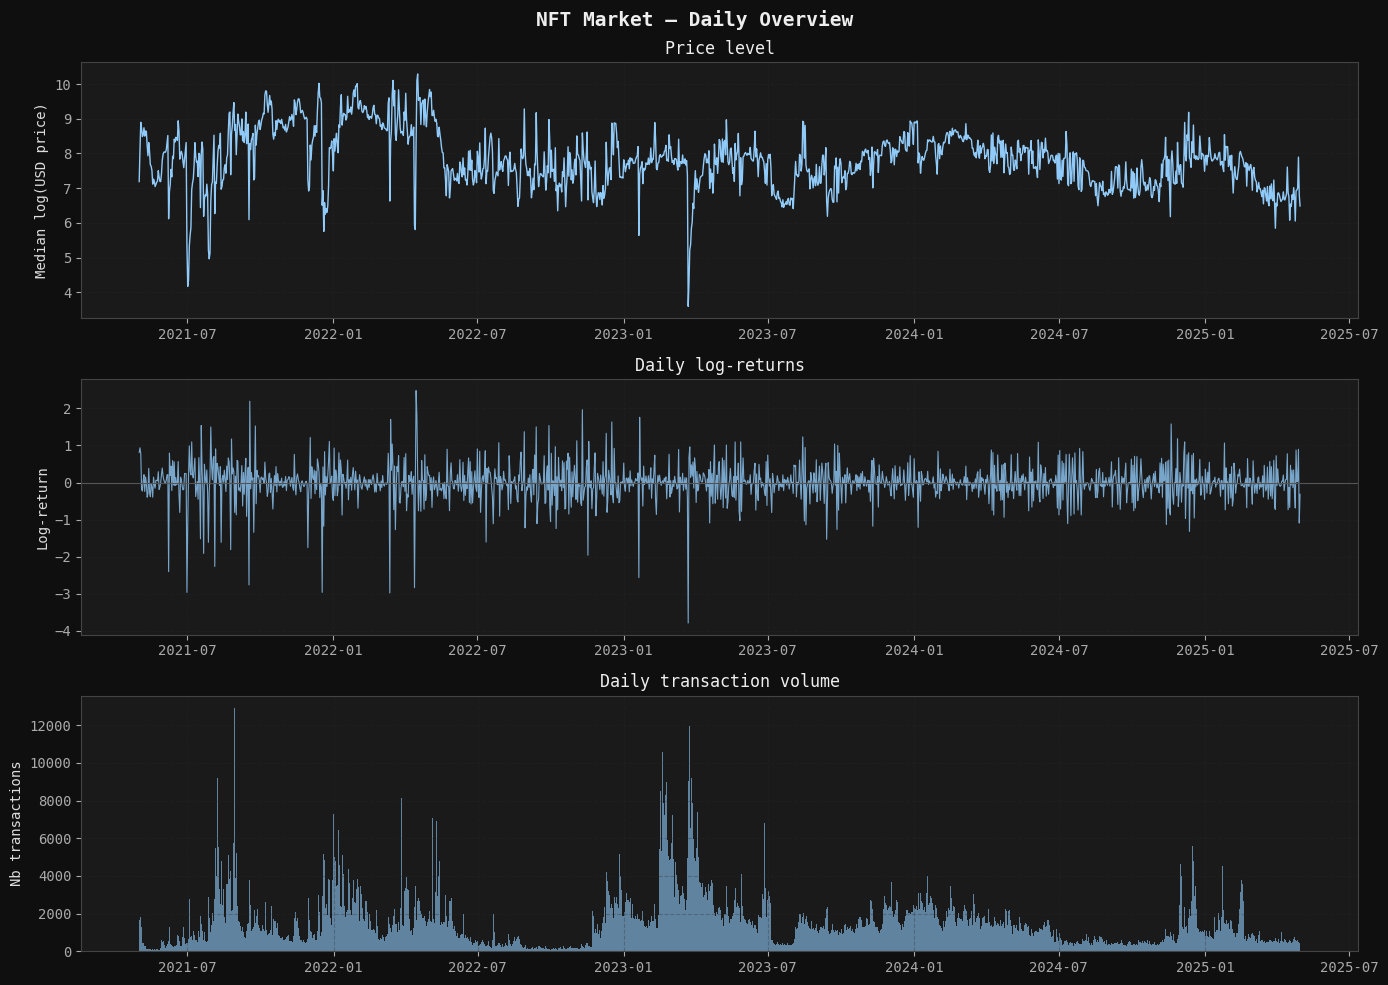


📊 FINAL SUMMARY
Days with data : 1460
Total transactions : 2,287,920
Analysis period : 2021-05-02 → 2025-04-30
Total log-return over the period : -0.7040


In [2]:
# ============================================================
# BLOCK 1 — Preprocessing & Daily Aggregation
# ============================================================

# ── 1.0 Timestamp format check ────────────────────
print("🔍 CHECK - timestamp format:")
print("Raw value examples:")
print(df_raw.select("event_timestamp").head(5))

# Try several date formats
sample_ts = df_raw["event_timestamp"].head(1).to_list()[0]
print(f"\nFirst timestamp : '{sample_ts}'")
print(f"Current dtype : {df_raw['event_timestamp'].dtype}")

# Detect the format automatically
if "T" in str(sample_ts):
    date_format = "%Y-%m-%dT%H:%M:%S"
    print(f"Detected format (with T) : {date_format}")
elif " " in str(sample_ts):
    date_format = "%Y-%m-%d %H:%M:%S"
    print(f"Detected format (with space) : {date_format}")
else:
    date_format = None
    print("⚠️ Non-standard format, check manually")

# ── 1.1 Parse timestamp & cast types (with fallback) ────────
if date_format:
    df = df_raw.with_columns([
        pl.col("event_timestamp")
          .str.strptime(pl.Datetime, format=date_format, strict=False)
          .alias("event_timestamp_parsed"),
        pl.col("log_usd_price").cast(pl.Float64),
        pl.col("payment_usd_price").cast(pl.Float64),
        pl.col("quantity").cast(pl.Float64),
        pl.col("avg_gas_price").cast(pl.Float64),
    ])
else:
    # Essayer parsing automatique
    df = df_raw.with_columns([
        pl.col("event_timestamp").str.strptime(pl.Datetime, strict=False).alias("event_timestamp_parsed"),
        pl.col("log_usd_price").cast(pl.Float64),
        pl.col("payment_usd_price").cast(pl.Float64),
        pl.col("quantity").cast(pl.Float64),
        pl.col("avg_gas_price").cast(pl.Float64),
    ])

# Check the conversion
null_count = df.filter(pl.col("event_timestamp_parsed").is_null()).shape[0]
print(f"\n📊 Timestamp parsing : {null_count:,} nulls out of {df.shape[0]:,} rows")

if null_count == df.shape[0]:
    print("❌ ALL timestamps are null: wrong format.")
    print("Problematic values:")
    print(df_raw.select("event_timestamp").head(10))
    raise ValueError("Timestamp parsing failed - check the format")

# Keep rows with a valid timestamp only
df = df.with_columns([
    pl.col("event_timestamp_parsed").dt.date().alias("date")
])

# ── 1.2 Keep valid rows ─────────────────────────
initial_rows = df.shape[0]
df = df.filter(
    pl.col("event_timestamp_parsed").is_not_null() &
    pl.col("log_usd_price").is_not_null() &
    pl.col("log_usd_price").is_finite() &
    (pl.col("payment_usd_price") > 0)
)

print(f"\n🧹 Cleaning : {initial_rows - df.shape[0]:,} rows removed")
print(f"✅ Remaining rows : {df.shape[0]:,}")

if df.shape[0] == 0:
    print("\n❌ ERROR: no row left after filtering!")
    print("Checking conditions:")
    print(f"  - event_timestamp non-null : {df_raw['event_timestamp'].null_count():,}")
    print(f"  - log_usd_price non-null   : {df_raw['log_usd_price'].null_count():,}")
    print(f"  - log_usd_price infini?    : {df_raw['log_usd_price'].is_infinite().sum() if df_raw['log_usd_price'].dtype in [pl.Float64, pl.Float32] else 'N/A'}")
    print(f"  - payment_usd_price > 0    : {(df_raw['payment_usd_price'] > 0).sum():,}")
    raise ValueError("Filter too strict - adjust conditions")

# ── 1.3 Daily aggregation ────────────────────────────────────
daily = (
    df
    .group_by("date")
    .agg([
        pl.col("log_usd_price").median().alias("log_price"),
        pl.col("log_usd_price").std().alias("log_price_std"),
        pl.col("payment_usd_price").median().alias("usd_price"),
        pl.col("log_usd_price").count().alias("volume"),
        pl.col("quantity").sum().alias("quantity_sold"),
        pl.col("avg_gas_price").median().alias("gas_price"),
    ])
    .sort("date")
)

print(f"\n📅 Daily series : {daily.shape[0]} days")
print(f"Period : {daily['date'].min()} → {daily['date'].max()}")
print("\nPreview:")
print(daily.head(5))

# ── 1.4 Compute log-returns ──────────────────────────────────
daily = daily.with_columns([
    (pl.col("log_price") - pl.col("log_price").shift(1)).alias("log_return")
]).filter(pl.col("log_return").is_not_null() & pl.col("log_return").is_finite())

print(f"\n📈 After computing returns : {daily.shape[0]} days")

if daily.shape[0] == 0:
    print("❌ Not enough data to compute returns")
    raise ValueError("Time series too short")

# ── 1.5 Descriptive stats ────────────────────────────────────
print("\n── Log-return statistics ──")
lr = daily["log_return"].to_numpy()
print(f"  Mean     : {lr.mean():.6f}")
print(f"  Std      : {lr.std():.6f}")
print(f"  Skew     : {stats.skew(lr):.4f}")
print(f"  Kurtosis : {stats.kurtosis(lr):.4f}")
print(f"  Min/Max  : {lr.min():.4f} / {lr.max():.4f}")

# ── 1.6 Plots ────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)
fig.suptitle("NFT Market — Daily Overview", fontsize=14, fontweight="bold")

dates = daily["date"].to_numpy()

# Log-price
axes[0].plot(dates, daily["log_price"].to_numpy(), color=NEUTRAL_COLOR, lw=1)
axes[0].set_ylabel("Median log(USD price)")
axes[0].set_title("Price level")
axes[0].grid(True, alpha=0.3)

# Log-returns
axes[1].plot(dates, daily["log_return"].to_numpy(), color=NEUTRAL_COLOR, lw=0.8, alpha=0.8)
axes[1].axhline(0, color="#555", lw=0.8)
axes[1].set_ylabel("Log-return")
axes[1].set_title("Daily log-returns")
axes[1].grid(True, alpha=0.3)

# Volume
axes[2].bar(dates, daily["volume"].to_numpy(), color=NEUTRAL_COLOR, alpha=0.6, width=1)
axes[2].set_ylabel("Transactions")
axes[2].set_title("Daily transaction volume")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ── 1.7 Summary ─────────────────────────
print("\n" + "="*60)
print("📊 FINAL SUMMARY")
print("="*60)
print(f"Days with data : {daily.shape[0]}")
print(f"Total transactions : {daily['volume'].sum():,}")
print(f"Analysis period : {daily['date'].min()} → {daily['date'].max()}")
print(f"Total log-return over the period : {(daily['log_price'].to_numpy()[-1] - daily['log_price'].to_numpy()[0]):.4f}")

Exogenous signals: momentum (7/14/30-day mean return), relative volume (vs 30-day average), gas-price z-score and 14-day realised volatility. Short-horizon momentum correlates +0.35 with the *same-day* return because the 7-day window includes that day; it is not a predictive correlation.

Rows after warmup drop : 1431 days
Date range             : 2021-05-31 → 2025-04-30
shape: (5, 8)
┌────────────┬────────────┬────────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ date       ┆ log_return ┆ momentum_7 ┆ momentum_ ┆ momentum_ ┆ rel_volum ┆ gas_zscor ┆ realized_ │
│ ---        ┆ ---        ┆ ---        ┆ 14        ┆ 30        ┆ e         ┆ e         ┆ vol_14    │
│ date       ┆ f64        ┆ f64        ┆ ---       ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│            ┆            ┆            ┆ f64       ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞════════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ 2021-05-31 ┆ 0.391386   ┆ 0.090422   ┆ 0.0118    ┆ 0.047359  ┆ 1.461583  ┆ -0.94645  ┆ 0.208128  │
│ 2021-06-01 ┆ 0.171888   ┆ 0.108725   ┆ 0.032994  ┆ 0.026062  ┆ 1.815832  ┆ -0.967883 ┆ 0.208253  │
│ 2021-06-02 ┆ 0.06723    ┆ 0.076582   ┆ 0.065969  ┆ -0.002897 ┆ 1.233299  ┆ -0.91081  ┆ 0.168

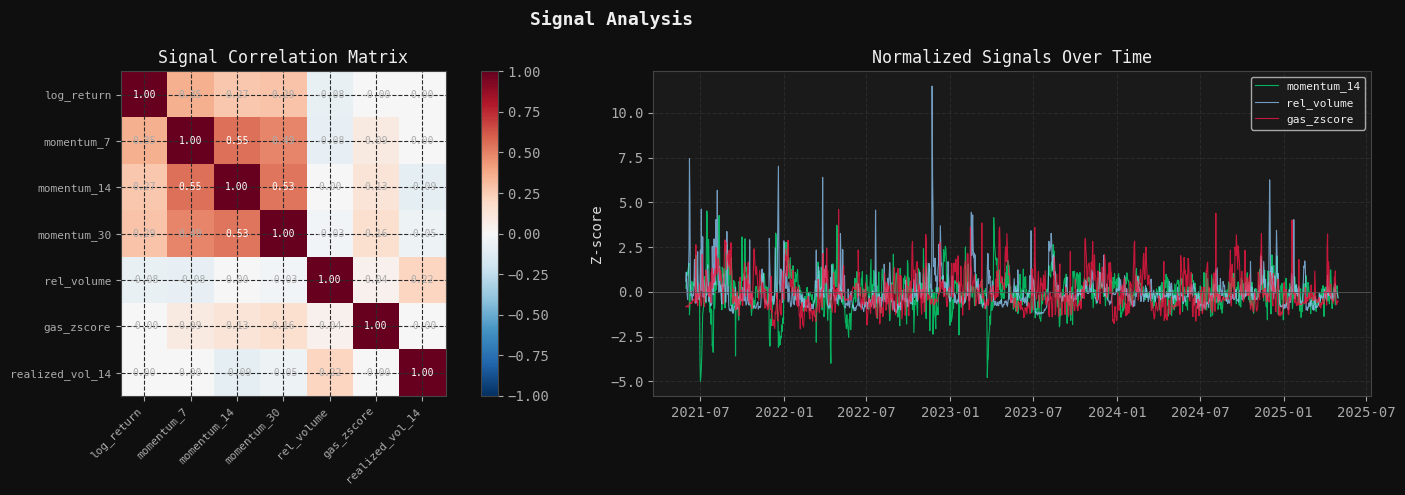


── Top 5 correlations with log_return ──
  momentum_7           +0.3526
  momentum_30          +0.2867
  momentum_14          +0.2723
  rel_volume           -0.0781
  realized_vol_14      +0.0021


In [3]:
# ============================================================
# BLOCK 2 — Signal Construction (Polars-only, no pyarrow)
# ============================================================
# Three exogenous signals to enrich the HMM:
#   S1 — Momentum    : rolling mean of log-returns (trend)
#   S2 — Rel. Volume : daily volume vs rolling average (activity)
#   S3 — Gas price   : normalized on-chain gas (speculation proxy)
# ============================================================

WINDOW_SHORT  = 7    # ~1 week
WINDOW_MEDIUM = 14   # ~2 weeks
WINDOW_LONG   = 30   # ~1 month

# ── 2.1  Momentum signals ────────────────────────────────────
daily = (
    daily
    .with_columns([
        # Short-term momentum
        pl.col("log_return")
          .rolling_mean(window_size=WINDOW_SHORT)
          .alias("momentum_7"),

        # Medium-term momentum
        pl.col("log_return")
          .rolling_mean(window_size=WINDOW_MEDIUM)
          .alias("momentum_14"),

        # Long-term momentum
        pl.col("log_return")
          .rolling_mean(window_size=WINDOW_LONG)
          .alias("momentum_30"),

        # Realized volatility (rolling std of returns)
        pl.col("log_return")
          .rolling_std(window_size=WINDOW_MEDIUM)
          .alias("realized_vol_14"),
    ])
)

# ── 2.2  Volume signal ───────────────────────────────────────
daily = (
    daily
    .with_columns([
        pl.col("volume")
          .rolling_mean(window_size=WINDOW_LONG)
          .alias("volume_ma30"),
    ])
    .with_columns([
        # Relative volume: how much above/below the 30-day average
        (pl.col("volume") / (pl.col("volume_ma30") + 1e-8))
          .alias("rel_volume"),
    ])
)

# ── 2.3  Gas price signal ────────────────────────────────────
daily = (
    daily
    .with_columns([
        pl.col("gas_price")
          .rolling_mean(window_size=WINDOW_LONG)
          .alias("gas_ma30"),
        pl.col("gas_price")
          .rolling_std(window_size=WINDOW_LONG)
          .alias("gas_std30"),
    ])
    .with_columns([
        # Z-score normalization of gas price
        ((pl.col("gas_price") - pl.col("gas_ma30")) /
         (pl.col("gas_std30") + 1e-8))
          .alias("gas_zscore"),
    ])
)

# ── 2.4  Drop warmup rows (NaNs from rolling windows) ────────
daily_signals = (
    daily
    .filter(
        pl.col("momentum_30").is_not_null() &
        pl.col("momentum_30").is_finite() &
        pl.col("rel_volume").is_not_null() &
        pl.col("rel_volume").is_finite() &
        pl.col("gas_zscore").is_not_null() &
        pl.col("gas_zscore").is_finite()
    )
)

print(f"Rows after warmup drop : {daily_signals.shape[0]} days")
print(f"Date range             : {daily_signals['date'].min()} → {daily_signals['date'].max()}")
print(daily_signals.select([
    "date", "log_return",
    "momentum_7", "momentum_14", "momentum_30",
    "rel_volume", "gas_zscore", "realized_vol_14"
]).head(5))

# ── 2.5  Signal statistics ───────────────────────────────────
print("\n── Signal statistics ──")
for col in ["momentum_7", "momentum_14", "momentum_30",
            "rel_volume", "gas_zscore", "realized_vol_14"]:
    arr = daily_signals[col].to_numpy()
    print(f"  {col:<20} mean={arr.mean():+.4f}  std={arr.std():.4f}  "
          f"min={arr.min():.4f}  max={arr.max():.4f}")

# ── 2.6  Correlation matrix (Polars native method) ──────────
signal_cols = ["log_return", "momentum_7", "momentum_14",
               "momentum_30", "rel_volume", "gas_zscore", "realized_vol_14"]

# Compute correlation matrix using Polars
corr_matrix = []
for col1 in signal_cols:
    row = []
    for col2 in signal_cols:
        corr = daily_signals.select(pl.corr(col1, col2)).item()
        row.append(corr)
    corr_matrix.append(row)

corr_matrix = np.array(corr_matrix)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Signal Analysis", fontsize=13, fontweight="bold")

# Correlation heatmap
im = axes[0].imshow(corr_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(signal_cols)))
axes[0].set_yticks(range(len(signal_cols)))
axes[0].set_xticklabels(signal_cols, rotation=45, ha="right", fontsize=8)
axes[0].set_yticklabels(signal_cols, fontsize=8)
for i in range(len(signal_cols)):
    for j in range(len(signal_cols)):
        axes[0].text(j, i, f"{corr_matrix[i,j]:.2f}",
                     ha="center", va="center", fontsize=7,
                     color="white" if abs(corr_matrix[i,j]) > 0.5 else "#aaa")
plt.colorbar(im, ax=axes[0])
axes[0].set_title("Signal Correlation Matrix")

# Signal time series (normalized)
dates_sig = daily_signals["date"].to_numpy()
for col, color in zip(
    ["momentum_14", "rel_volume", "gas_zscore"],
    [BULL_COLOR, NEUTRAL_COLOR, BEAR_COLOR]
):
    arr = daily_signals[col].to_numpy()
    arr_norm = (arr - arr.mean()) / (arr.std() + 1e-8)
    axes[1].plot(dates_sig, arr_norm, lw=0.8, alpha=0.75,
                 label=col, color=color)

axes[1].axhline(0, color="#555", lw=0.6)
axes[1].set_title("Normalized Signals Over Time")
axes[1].set_ylabel("Z-score")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# ── 2.7  Correlation summary (optional) ─────────────────────
print("\n── Top 5 correlations with log_return ──")
corr_with_return = [
    (col, daily_signals.select(pl.corr("log_return", col)).item())
    for col in signal_cols[1:]  # exclude log_return itself
]
corr_with_return.sort(key=lambda x: abs(x[1]), reverse=True)
for col, corr_val in corr_with_return[:5]:
    print(f"  {col:<20} {corr_val:+.4f}")

## Part A · Two-state hidden Markov model (validation on synthetic data)

$$s_t \in \{\text{Bear}, \text{Bull}\}, \qquad r_t \mid s_t \sim \mathcal N(\mu_{s_t}, \sigma^2_{s_t}), \qquad P(s_{t+1} \mid s_t) = A_{s_t,\cdot}\ \text{(modulated by the signals)}$$

**Protocol.** Simulate 1,430 days from a known HMM whose transitions are driven by the *real* signals above (μ = ±0.025, σ = 0.55 / 0.35, regimes lasting ~20–30 days); fit a plain two-state HMM by Baum–Welch on the first half; then predict the state one step ahead, online, on the second half, and compare with the simulated truth.

N_TOTAL = 1431  |  T = 715  |  2T = 1430

── True model parameters ──
  μ  (bear, bull) = [-0.025  0.025]
  σ  (bear, bull) = [0.55 0.35]
  A  =
[[0.95  0.05 ]
 [0.033 0.967]]
  Signal weights  : momentum=0.3, volume=0.1, gas=-0.05

── Simulation results ──
  Total timesteps : 1430
  Bull days       : 862 (60.3%)
  Bear days       : 568 (39.7%)
  Return mean     : -0.00065
  Return std      : 0.45036

  Avg Bull duration : 34.5 days
  Avg Bear duration : 21.8 days
  Max Bull duration : 102 days
  Max Bear duration : 77 days


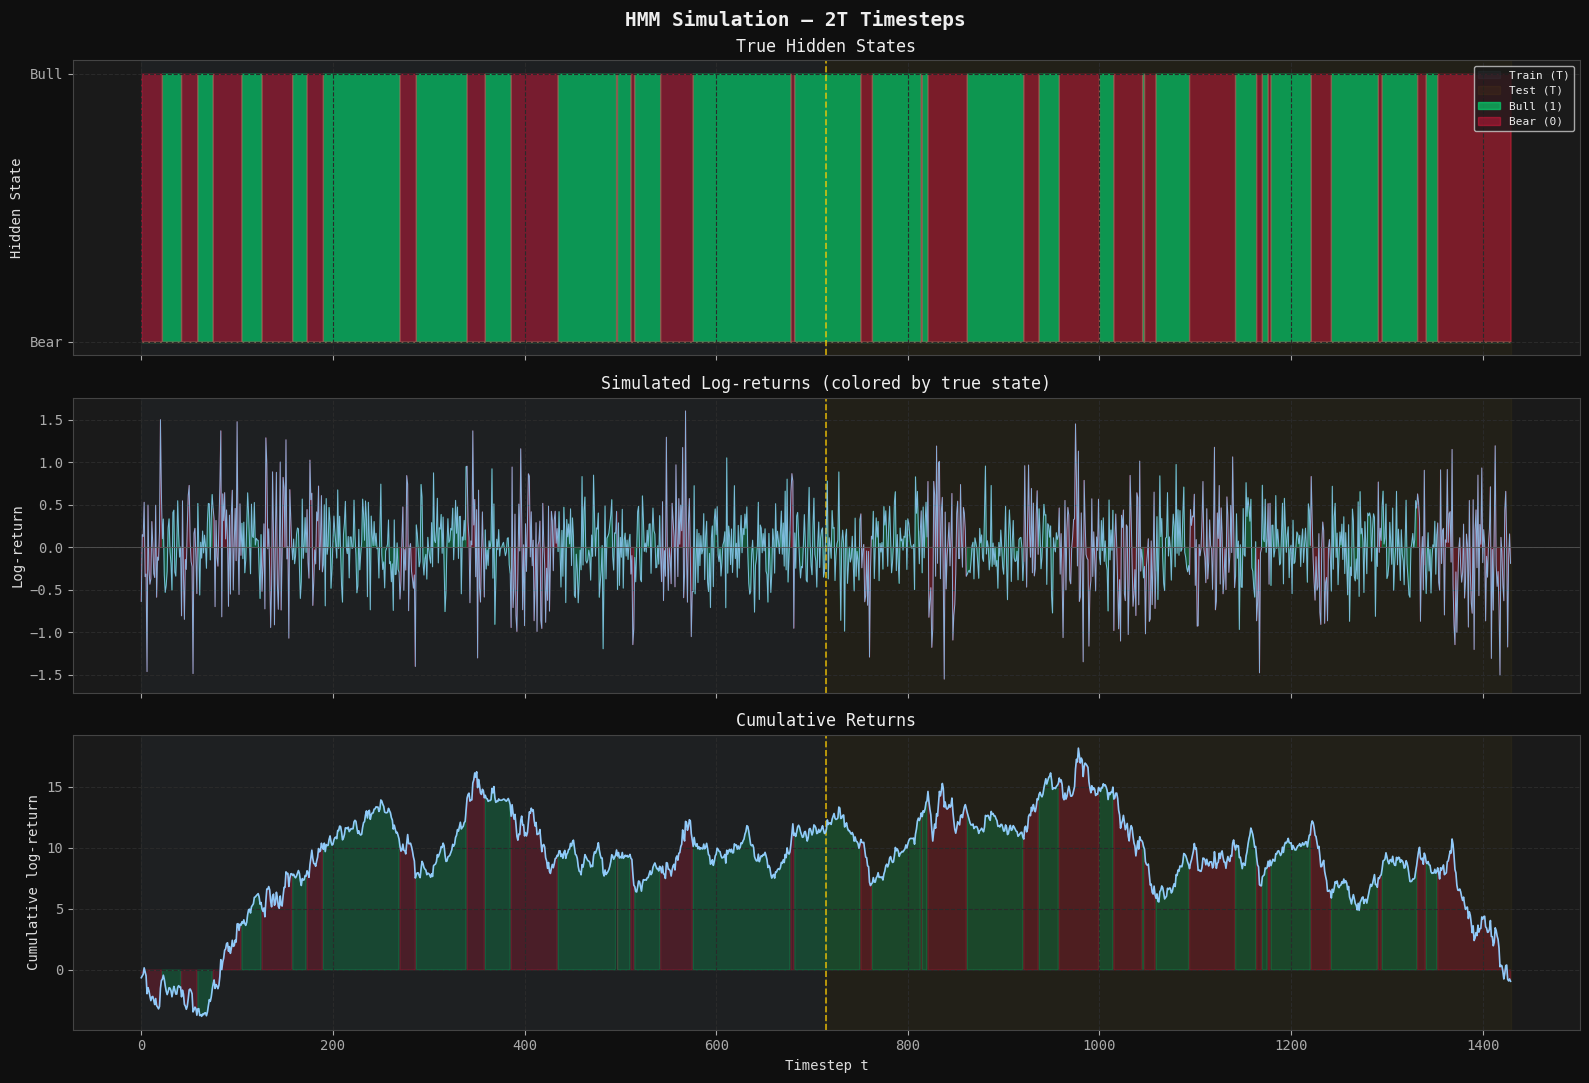


✅ Simulation stored. r_train: (715,), r_test: (715,)


In [4]:
# ============================================================
# BLOCK 3 — Model Simulation (2T timesteps)
# ============================================================
# We simulate a 2-state HMM with exogenous signals.
# The hidden state s_t ∈ {0=Bear, 1=Bull} follows a Markov chain.
# Observed log-return: r_t | s_t ~ N(μ(s_t), σ²(s_t))
# Transition probabilities are modulated by signals.
#
# Realistic parameters are calibrated from Block 2 statistics:
#   - μ_bear, μ_bull from observed mean log-returns
#   - σ_bear, σ_bull from realized_vol_14 quantiles
#   - Transition matrix from typical crypto regime durations
# ============================================================

np.random.seed(42)

# ── 3.1  Define T ────────────────────────────────────────────
N_TOTAL = daily_signals.shape[0]   # 1431
T       = N_TOTAL // 2             # 715  → train / test split
print(f"N_TOTAL = {N_TOTAL}  |  T = {T}  |  2T = {2*T}")

# ── 3.2  Realistic model parameters ─────────────────────────
# Derived from Block 2 stats:
#   std(log_return) = 0.50
#   realized_vol_14 mean = 0.457, range [0.07, 1.24]
#   momentum correlations suggest persistent regimes

PARAMS_TRUE = {
    # Emission parameters
    "mu":    np.array([-0.025,  0.025]),   # bear drift, bull drift
    "sigma": np.array([ 0.55,   0.35]),    # bear vol,   bull vol

    # Baseline transition matrix (before signal modulation)
    # P[i,j] = prob of going from state i to state j
    # Bear regime lasts ~20 days → p(stay bear) = 0.95
    # Bull regime lasts ~30 days → p(stay bull) = 0.967
    "A": np.array([
        [0.950, 0.050],   # from Bear: 95% stay, 5% switch to Bull
        [0.033, 0.967],   # from Bull: 3.3% switch to Bear, 96.7% stay
    ]),

    # Signal weights (how much each signal modulates transitions)
    # Positive weight on momentum → high momentum favors Bull
    "w_momentum": 0.30,
    "w_volume":   0.10,
    "w_gas":     -0.05,   # high gas slightly bearish (congestion)

    # Initial state distribution
    "pi": np.array([0.45, 0.55]),  # slightly more bull at start
}

print("\n── True model parameters ──")
print(f"  μ  (bear, bull) = {PARAMS_TRUE['mu']}")
print(f"  σ  (bear, bull) = {PARAMS_TRUE['sigma']}")
print(f"  A  =\n{PARAMS_TRUE['A']}")
print(f"  Signal weights  : momentum={PARAMS_TRUE['w_momentum']}, "
      f"volume={PARAMS_TRUE['w_volume']}, gas={PARAMS_TRUE['w_gas']}")

# ── 3.3  Signal-modulated transition probabilities ───────────
def modulated_transition(A, momentum, volume, gas, w_mom, w_vol, w_gas):
    """
    Modulate transition matrix with signals via softmax.
    Higher momentum → higher prob of staying in / switching to Bull.
    Returns a valid 2x2 stochastic matrix.
    """
    # Signal composite score (positive = bullish pressure)
    signal = w_mom * momentum + w_vol * (volume - 1.0) + w_gas * gas

    # Modulate log-odds of transition
    A_mod = A.copy()
    # Increase p(bull→bull) and p(bear→bull) when signal is positive
    A_mod[0, 1] = A[0, 1] * np.exp( signal)   # bear→bull
    A_mod[1, 0] = A[1, 0] * np.exp(-signal)   # bull→bear
    A_mod[0, 0] = 1 - A_mod[0, 1]
    A_mod[1, 1] = 1 - A_mod[1, 0]

    # Clip to valid probability range
    A_mod = np.clip(A_mod, 1e-6, 1 - 1e-6)
    A_mod[0] /= A_mod[0].sum()
    A_mod[1] /= A_mod[1].sum()
    return A_mod

# ── 3.4  Extract real signals for simulation ─────────────────
# We use the REAL signals from the dataset to drive the simulation
# This grounds the simulation in realistic signal dynamics

sig_momentum = daily_signals["momentum_14"].to_numpy()
sig_volume   = np.clip(daily_signals["rel_volume"].to_numpy(), 0, 5)  # winsorize
sig_gas      = np.clip(daily_signals["gas_zscore"].to_numpy(), -3, 3) # winsorize

# ── 3.5  Simulate hidden states & observations ───────────────
n_sim    = 2 * T
states   = np.zeros(n_sim, dtype=int)
returns  = np.zeros(n_sim)

p = PARAMS_TRUE

# Initial state
states[0] = np.random.choice(2, p=p["pi"])
returns[0] = np.random.normal(p["mu"][states[0]], p["sigma"][states[0]])

for t in range(1, n_sim):
    # Use real signals (loop over available signal length)
    idx = t % len(sig_momentum)
    A_t = modulated_transition(
        p["A"],
        sig_momentum[idx],
        sig_volume[idx],
        sig_gas[idx],
        p["w_momentum"],
        p["w_volume"],
        p["w_gas"],
    )
    # Sample next state
    states[t]  = np.random.choice(2, p=A_t[states[t-1]])
    # Sample observation
    returns[t] = np.random.normal(p["mu"][states[t]], p["sigma"][states[t]])

print(f"\n── Simulation results ──")
print(f"  Total timesteps : {n_sim}")
print(f"  Bull days       : {states.sum()} ({100*states.mean():.1f}%)")
print(f"  Bear days       : {n_sim - states.sum()} ({100*(1-states.mean()):.1f}%)")
print(f"  Return mean     : {returns.mean():.5f}")
print(f"  Return std      : {returns.std():.5f}")

# Regime duration analysis
from itertools import groupby
durations_bull = [sum(1 for _ in g) for k, g in groupby(states) if k == 1]
durations_bear = [sum(1 for _ in g) for k, g in groupby(states) if k == 0]
print(f"\n  Avg Bull duration : {np.mean(durations_bull):.1f} days")
print(f"  Avg Bear duration : {np.mean(durations_bear):.1f} days")
print(f"  Max Bull duration : {np.max(durations_bull)} days")
print(f"  Max Bear duration : {np.max(durations_bear)} days")

# ── 3.6  Visualization ───────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(16, 11), sharex=True)
fig.suptitle("HMM Simulation — 2T Timesteps", fontsize=14, fontweight="bold")

t_axis = np.arange(n_sim)

# Background shading: bull = green, bear = red
for ax in axes:
    ax.axvspan(0,   T, alpha=0.04, color=NEUTRAL_COLOR, label="Train (T)")
    ax.axvspan(T, n_sim, alpha=0.04, color="#ffcc00",   label="Test (T)")
    ax.axvline(T, color="#ffcc00", lw=1.2, ls="--", alpha=0.8)

# Panel 1: Hidden states
axes[0].fill_between(t_axis, states, step="mid",
                     color=BULL_COLOR, alpha=0.6, label="Bull (1)")
axes[0].fill_between(t_axis, 1 - states, step="mid",
                     color=BEAR_COLOR, alpha=0.4, label="Bear (0)")
axes[0].set_ylabel("Hidden State")
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["Bear", "Bull"])
axes[0].set_title("True Hidden States")
axes[0].legend(loc="upper right", fontsize=8)

# Panel 2: Simulated returns
axes[1].plot(t_axis, returns, color=NEUTRAL_COLOR, lw=0.7, alpha=0.85)
axes[1].axhline(0, color="#555", lw=0.6)
# Color by state
bull_mask = states == 1
axes[1].fill_between(t_axis, returns, 0,
                     where=bull_mask,  color=BULL_COLOR, alpha=0.25)
axes[1].fill_between(t_axis, returns, 0,
                     where=~bull_mask, color=BEAR_COLOR, alpha=0.25)
axes[1].set_ylabel("Log-return")
axes[1].set_title("Simulated Log-returns (colored by true state)")

# Panel 3: Cumulative returns
cum_returns = np.cumsum(returns)
axes[2].plot(t_axis, cum_returns, color=NEUTRAL_COLOR, lw=1.2)
axes[2].fill_between(t_axis, cum_returns, 0,
                     where=bull_mask,  color=BULL_COLOR, alpha=0.2)
axes[2].fill_between(t_axis, cum_returns, 0,
                     where=~bull_mask, color=BEAR_COLOR, alpha=0.2)
axes[2].set_ylabel("Cumulative log-return")
axes[2].set_title("Cumulative Returns")
axes[2].set_xlabel("Timestep t")

plt.tight_layout()
plt.show()

# ── 3.7  Store simulation arrays for next blocs ──────────────
sim = {
    "returns"     : returns,
    "states"      : states,
    "signals_mom" : sig_momentum[:n_sim % len(sig_momentum) + n_sim],
    "signals_vol" : sig_volume,
    "signals_gas" : sig_gas,
    "T"           : T,
    "n_sim"       : n_sim,
    "params_true" : PARAMS_TRUE,
}

# Convenience splits
r_train  = returns[:T]
s_train  = states[:T]
r_test   = returns[T:]
s_test   = states[T:]

print(f"\n✅ Simulation stored. r_train: {r_train.shape}, r_test: {r_test.shape}")

Running Baum-Welch on training set (T=715)...
  Restart 0: converged at iter 97, ll=-418.1163
  Restart 1: converged at iter 129, ll=-418.1163
  Restart 2: converged at iter 167, ll=-418.1163
  Restart 3: converged at iter 121, ll=-418.1163
  Restart 4: converged at iter 151, ll=-418.1163

── Calibrated parameters ──
  μ̂  (bear, bull) = [0.0076 0.0209]
  σ̂  (bear, bull) = [0.5786 0.3315]
  Â  =
[[0.9186 0.0814]
 [0.0503 0.9497]]
  π̂  = [1. 0.]

  True μ  = [-0.025  0.025]
  True σ  = [0.55 0.35]
  True A  =
[[0.95  0.05 ]
 [0.033 0.967]]

── Parameter recovery error ──
  Δμ    = [0.0326 0.0041]
  Δσ    = [0.0286 0.0185]
  ΔA    = [[0.0314 0.0314]
 [0.0173 0.0173]]


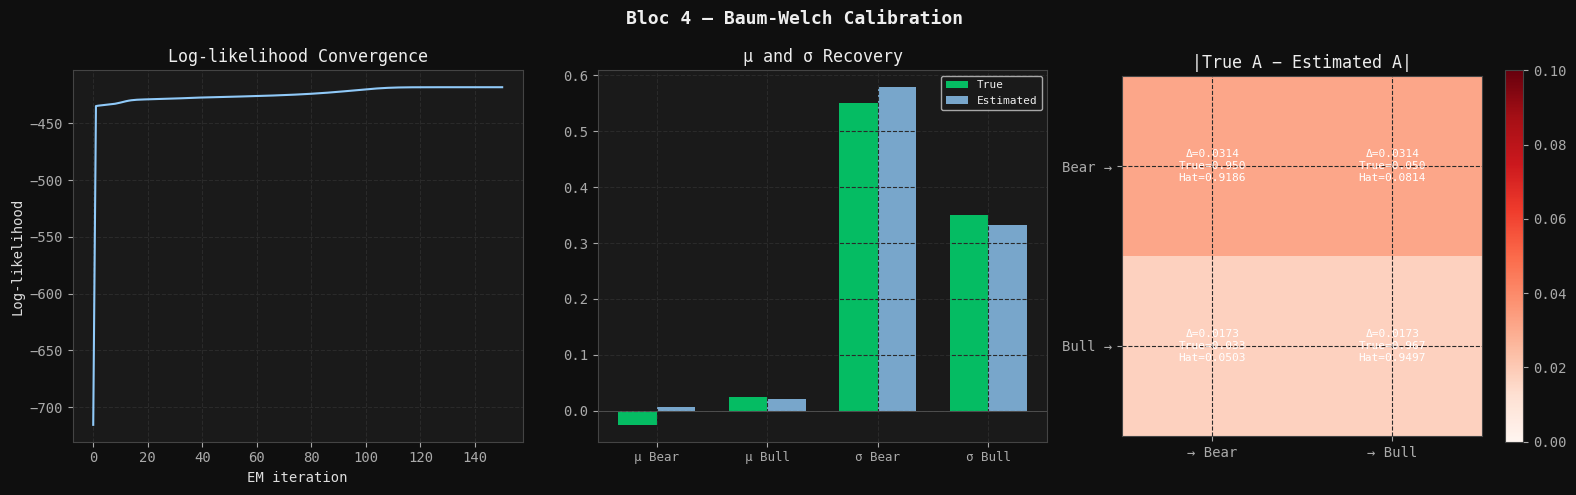


✅ Calibrated parameters stored in `calibrated` dict.


In [5]:
# ============================================================
# BLOCK 4 — Calibration (Baum-Welch EM Algorithm)
# ============================================================
# We calibrate the HMM on the first T timesteps (r_train).
# The Baum-Welch algorithm iterates:
#   E-step : forward-backward to compute state posteriors
#   M-step : update μ, σ, A, π to maximize expected log-likelihood
#
# Signals are NOT used in calibration (unsupervised).
# We recover μ, σ, A from observations alone.
# ============================================================

# ── 4.1  Gaussian emission log-probability ───────────────────
def log_emission(r, mu, sigma):
    """
    Log p(r_t | state k) for all t and k.
    Returns array of shape (T, K).
    """
    T_, K = len(r), len(mu)
    log_b = np.zeros((T_, K))
    for k in range(K):
        log_b[:, k] = stats.norm.logpdf(r, loc=mu[k], scale=sigma[k])
    return log_b


# ── 4.2  Forward algorithm (log-space) ───────────────────────
def forward(log_b, A, pi):
    """
    Forward pass in log-space.
    Returns:
        alpha : (T, K) log forward probabilities
        log_likelihood : scalar
    """
    T_, K = log_b.shape
    alpha = np.zeros((T_, K))

    # t = 0
    alpha[0] = np.log(pi + 1e-300) + log_b[0]

    for t in range(1, T_):
        for k in range(K):
            alpha[t, k] = logsumexp(alpha[t-1] + np.log(A[:, k] + 1e-300)) + log_b[t, k]

    log_lik = logsumexp(alpha[-1])
    return alpha, log_lik


# ── 4.3  Backward algorithm (log-space) ──────────────────────
def backward(log_b, A):
    """
    Backward pass in log-space.
    Returns beta : (T, K) log backward probabilities.
    """
    T_, K = log_b.shape
    beta = np.zeros((T_, K))
    # beta[-1] = log(1) = 0 by definition

    for t in range(T_ - 2, -1, -1):
        for k in range(K):
            beta[t, k] = logsumexp(
                np.log(A[k, :] + 1e-300) + log_b[t+1, :] + beta[t+1, :]
            )
    return beta


# ── 4.4  E-step: compute gamma and xi ────────────────────────
def e_step(alpha, beta, log_b, A):
    """
    Compute:
        gamma[t,k] = P(s_t=k | observations)   shape (T, K)
        xi[t,i,j]  = P(s_t=i, s_{t+1}=j | obs) shape (T-1, K, K)
    """
    T_, K = alpha.shape

    # gamma
    log_gamma = alpha + beta
    log_gamma -= logsumexp(log_gamma, axis=1, keepdims=True)
    gamma = np.exp(log_gamma)

    # xi
    xi = np.zeros((T_ - 1, K, K))
    for t in range(T_ - 1):
        for i in range(K):
            for j in range(K):
                xi[t, i, j] = (alpha[t, i]
                                + np.log(A[i, j] + 1e-300)
                                + log_b[t+1, j]
                                + beta[t+1, j])
        xi[t] = np.exp(xi[t] - logsumexp(xi[t].ravel()))

    return gamma, xi


# ── 4.5  M-step: update parameters ───────────────────────────
def m_step(r, gamma, xi):
    """
    Re-estimate μ, σ, A, π from sufficient statistics.
    """
    K = gamma.shape[1]

    pi_new    = gamma[0] / gamma[0].sum()
    mu_new    = np.zeros(K)
    sigma_new = np.zeros(K)
    A_new     = np.zeros((K, K))

    for k in range(K):
        w = gamma[:, k]
        w_sum = w.sum() + 1e-300
        mu_new[k]    = (w * r).sum() / w_sum
        sigma_new[k] = np.sqrt((w * (r - mu_new[k])**2).sum() / w_sum)
        sigma_new[k] = max(sigma_new[k], 1e-4)   # floor

    # Transition matrix
    xi_sum = xi.sum(axis=0)                       # (K, K)
    A_new  = xi_sum / (xi_sum.sum(axis=1, keepdims=True) + 1e-300)

    return mu_new, sigma_new, A_new, pi_new


# ── 4.6  Baum-Welch loop ─────────────────────────────────────
def baum_welch(r, K=2, n_iter=100, tol=1e-6, n_restarts=5, verbose=True):
    """
    Fit HMM via Baum-Welch with multiple random restarts.
    Returns best parameters (highest log-likelihood).
    """
    best_ll   = -np.inf
    best_params = None
    history_best = None

    for restart in range(n_restarts):
        np.random.seed(restart * 7 + 42)

        # Random initialization
        mu_    = np.random.choice(r, K) 
        sigma_ = np.abs(np.random.normal(r.std(), 0.1, K)) + 0.1
        # Ensure ordering: state 0 = lower mean (bear), state 1 = higher mean (bull)
        order  = np.argsort(mu_)
        mu_    = mu_[order]
        sigma_ = sigma_[order]

        # Random stochastic transition matrix
        A_ = np.random.dirichlet([8, 1], size=K)   # biased toward staying
        pi_= np.array([0.5, 0.5])

        ll_history = []
        prev_ll    = -np.inf

        for it in range(n_iter):
            log_b          = log_emission(r, mu_, sigma_)
            alpha, log_lik = forward(log_b, A_, pi_)
            beta           = backward(log_b, A_)
            gamma, xi      = e_step(alpha, beta, log_b, A_)
            mu_, sigma_, A_, pi_ = m_step(r, gamma, xi)

            # Re-enforce ordering (avoid label switching)
            if mu_[0] > mu_[1]:
                mu_    = mu_[::-1]
                sigma_ = sigma_[::-1]
                A_     = A_[::-1, :][:, ::-1]
                pi_    = pi_[::-1]
                gamma  = gamma[:, ::-1]

            ll_history.append(log_lik)

            if abs(log_lik - prev_ll) < tol:
                if verbose:
                    print(f"  Restart {restart}: converged at iter {it+1}, "
                          f"ll={log_lik:.4f}")
                break
            prev_ll = log_lik

        if log_lik > best_ll:
            best_ll      = log_lik
            best_params  = (mu_.copy(), sigma_.copy(), A_.copy(), pi_.copy())
            history_best = ll_history.copy()

    return best_params, best_ll, history_best


# ── 4.7  Run calibration ─────────────────────────────────────
print("Running Baum-Welch on training set (T=715)...")
(mu_hat, sigma_hat, A_hat, pi_hat), best_ll, ll_history = baum_welch(
    r_train, K=2, n_iter=200, tol=1e-6, n_restarts=5, verbose=True
)

print(f"\n── Calibrated parameters ──")
print(f"  μ̂  (bear, bull) = {mu_hat.round(4)}")
print(f"  σ̂  (bear, bull) = {sigma_hat.round(4)}")
print(f"  Â  =\n{A_hat.round(4)}")
print(f"  π̂  = {pi_hat.round(4)}")
print(f"\n  True μ  = {PARAMS_TRUE['mu']}")
print(f"  True σ  = {PARAMS_TRUE['sigma']}")
print(f"  True A  =\n{PARAMS_TRUE['A']}")

# ── 4.8  Recovery error ──────────────────────────────────────
print(f"\n── Parameter recovery error ──")
print(f"  Δμ    = {np.abs(mu_hat    - PARAMS_TRUE['mu']).round(4)}")
print(f"  Δσ    = {np.abs(sigma_hat - PARAMS_TRUE['sigma']).round(4)}")
print(f"  ΔA    = {np.abs(A_hat     - PARAMS_TRUE['A']).round(4)}")

# ── 4.9  Visualization ───────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Block 4 — Baum-Welch Calibration", fontsize=13, fontweight="bold")

# Log-likelihood convergence
axes[0].plot(ll_history, color=NEUTRAL_COLOR, lw=1.5)
axes[0].set_title("Log-likelihood Convergence")
axes[0].set_xlabel("EM iteration")
axes[0].set_ylabel("Log-likelihood")

# Parameter comparison: μ and σ
labels  = ["μ Bear", "μ Bull", "σ Bear", "σ Bull"]
true_v  = [PARAMS_TRUE["mu"][0], PARAMS_TRUE["mu"][1],
           PARAMS_TRUE["sigma"][0], PARAMS_TRUE["sigma"][1]]
hat_v   = [mu_hat[0], mu_hat[1], sigma_hat[0], sigma_hat[1]]

x = np.arange(len(labels))
w = 0.35
axes[1].bar(x - w/2, true_v, w, label="True",       color=BULL_COLOR,   alpha=0.8)
axes[1].bar(x + w/2, hat_v,  w, label="Estimated",  color=NEUTRAL_COLOR, alpha=0.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, fontsize=9)
axes[1].axhline(0, color="#555", lw=0.6)
axes[1].set_title("μ and σ Recovery")
axes[1].legend(fontsize=8)

# Transition matrix comparison
A_diff = np.abs(A_hat - PARAMS_TRUE["A"])
im = axes[2].imshow(A_diff, cmap="Reds", vmin=0, vmax=0.1)
axes[2].set_xticks([0, 1]); axes[2].set_yticks([0, 1])
axes[2].set_xticklabels(["→ Bear", "→ Bull"])
axes[2].set_yticklabels(["Bear →", "Bull →"])
for i in range(2):
    for j in range(2):
        axes[2].text(j, i,
                     f"Δ={A_diff[i,j]:.4f}\nTrue={PARAMS_TRUE['A'][i,j]:.3f}\nHat={A_hat[i,j]:.4f}",
                     ha="center", va="center", fontsize=8, color="white")
plt.colorbar(im, ax=axes[2])
axes[2].set_title("|True A − Estimated A|")

plt.tight_layout()
plt.show()

# ── 4.10  Store calibrated params ────────────────────────────
calibrated = {
    "mu"    : mu_hat,
    "sigma" : sigma_hat,
    "A"     : A_hat,
    "pi"    : pi_hat,
}
print("\n✅ Calibrated parameters stored in `calibrated` dict.")

**What is recovered.** Volatilities (0.58 / 0.33 vs 0.55 / 0.35) and regime persistence are recovered well. The drifts are not: the "bear" drift comes out at +0.008 instead of −0.025, because a drift of ±0.025 is 1/20 of a daily standard deviation and cannot be estimated from 715 observations. The two states are therefore identified as **high-volatility vs low-volatility** regimes, not as falling vs rising markets.

Running inference on training set (t = 1 → T)...
  Log-likelihood (filtered)  : -418.1163
  Log-likelihood (smoothed)  : -418.1163
  Viterbi log-prob           : -465.3321

── State at t = T (end of training) ──
  True state          : 1  (Bull)
  Filtered inference  : 1  (Bull)  [P(Bull)=0.9059]
  Smoothed inference  : 1  (Bull)  [P(Bull)=0.9059]
  Viterbi inference   : 1  (Bull)

── Training set accuracy ──
  Filtered  : 0.8294 (82.9%)
  Smoothed  : 0.9119 (91.2%)
  Viterbi   : 0.8727  (87.3%)

── Confusion matrix (Filtered) ──
  TN=176  FP=70
  FN=52  TP=417
  Precision : 0.8563
  Recall    : 0.8891


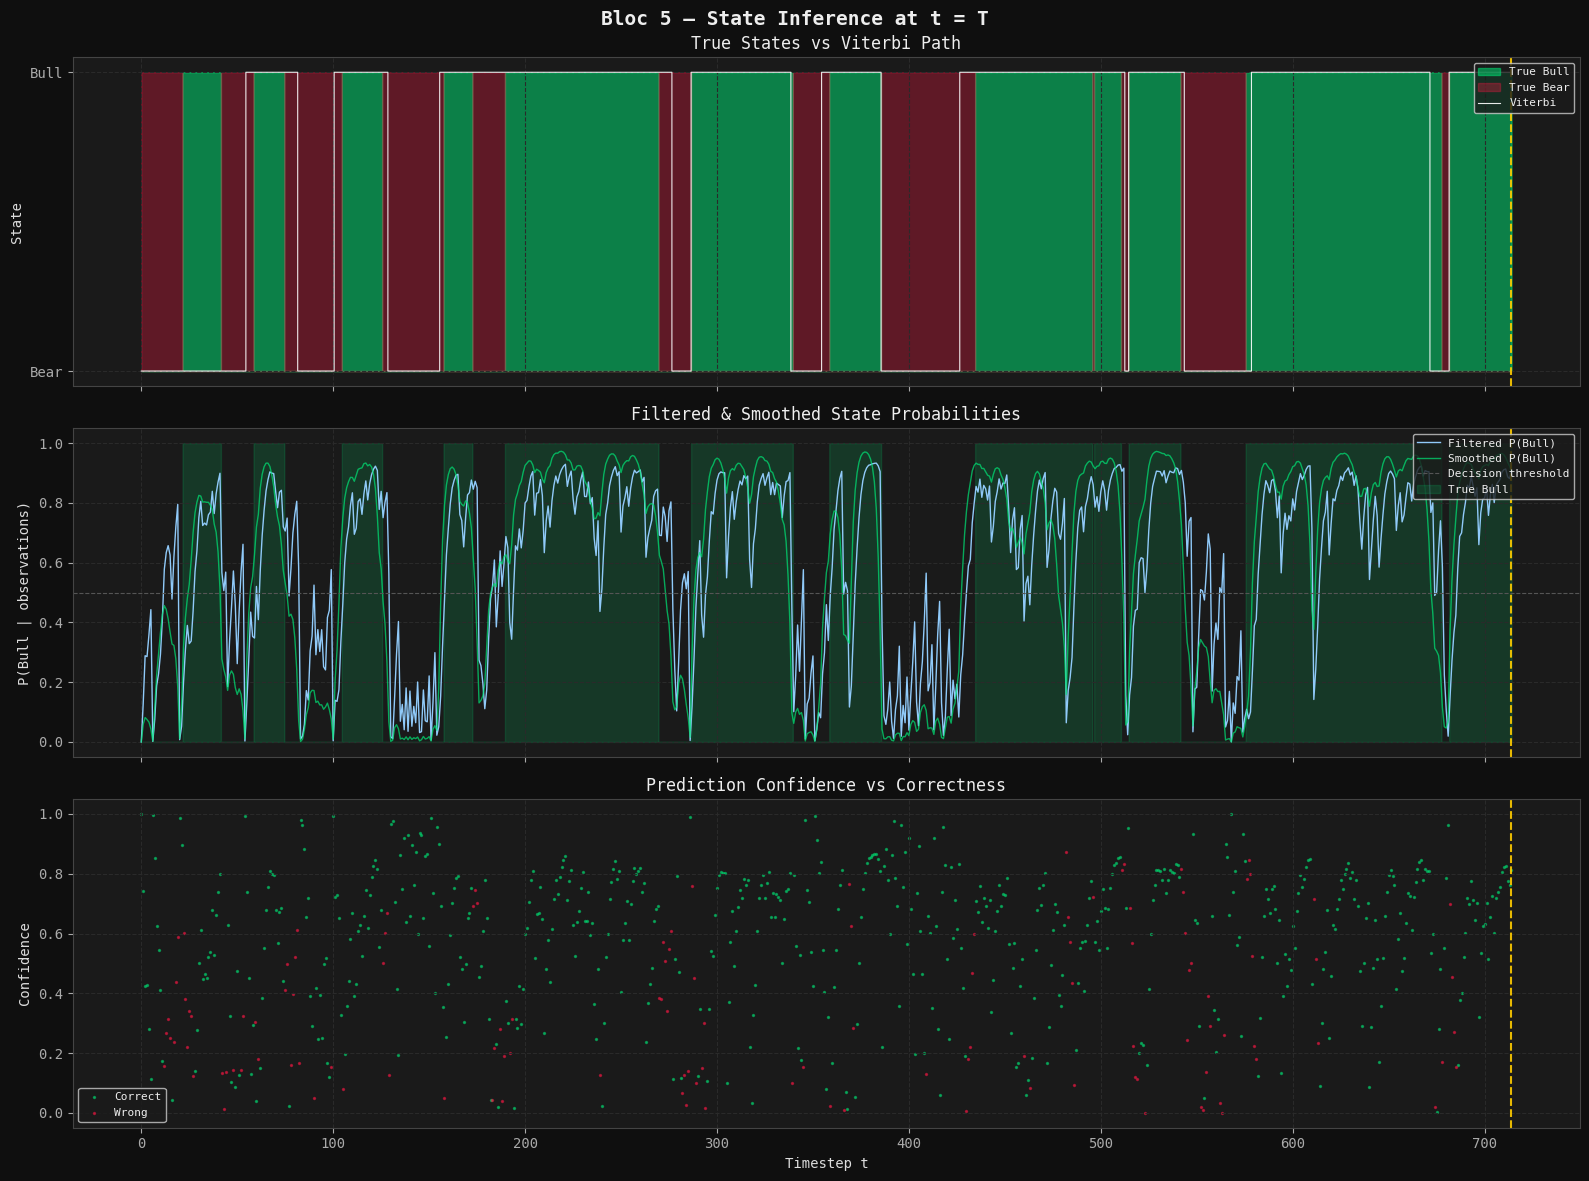


✅ Inference complete.
   State at t=T : Bull (P(Bull) = 0.9059)
   → This is the seed state for Block 6 predictions.


In [6]:
# ============================================================
# BLOCK 5 — State Inference at t = T (Forward Algorithm)
# ============================================================
# Given r_1, ..., r_T and calibrated parameters, we infer:
#   1. The filtered distribution P(s_t | r_1:t) for all t ≤ T
#      via the Forward algorithm
#   2. The most likely state sequence s_1*, ..., s_T*
#      via the Viterbi algorithm
#   3. The smoothed distribution P(s_t | r_1:T) for all t ≤ T
#      via the Forward-Backward algorithm
#
# The state at t = T is the starting point for Block 6 predictions.
# ============================================================

# ── 5.1  Filtered probabilities (Forward) ────────────────────
def filtered_probs(r, mu, sigma, A, pi):
    """
    Run forward algorithm and return filtered state probabilities.
    filtered[t, k] = P(s_t = k | r_1:t)
    Also returns log-likelihood.
    """
    log_b          = log_emission(r, mu, sigma)
    alpha, log_lik = forward(log_b, A, pi)

    # Convert log alpha to normalized probabilities
    # P(s_t=k | r_1:t) ∝ exp(alpha[t,k])
    log_filtered = alpha - logsumexp(alpha, axis=1, keepdims=True)
    filtered      = np.exp(log_filtered)
    return filtered, log_lik, alpha


# ── 5.2  Smoothed probabilities (Forward-Backward) ───────────
def smoothed_probs(r, mu, sigma, A, pi):
    """
    Run forward-backward and return smoothed state probabilities.
    smoothed[t, k] = P(s_t = k | r_1:T)
    """
    log_b          = log_emission(r, mu, sigma)
    alpha, log_lik = forward(log_b, A, pi)
    beta           = backward(log_b, A)

    log_smoothed = alpha + beta
    log_smoothed -= logsumexp(log_smoothed, axis=1, keepdims=True)
    smoothed      = np.exp(log_smoothed)
    return smoothed, log_lik


# ── 5.3  Viterbi algorithm ────────────────────────────────────
def viterbi(r, mu, sigma, A, pi):
    """
    Find the most likely state sequence via Viterbi.
    Returns:
        states_viterbi : (T,) array of most likely states
        log_prob       : log probability of the best path
    """
    T_, K  = len(r), len(mu)
    log_b  = log_emission(r, mu, sigma)
    log_A  = np.log(A + 1e-300)
    log_pi = np.log(pi + 1e-300)

    delta   = np.zeros((T_, K))   # best log-prob ending in state k at time t
    psi     = np.zeros((T_, K), dtype=int)  # backpointer

    delta[0] = log_pi + log_b[0]

    for t in range(1, T_):
        for k in range(K):
            scores      = delta[t-1] + log_A[:, k]
            psi[t, k]   = np.argmax(scores)
            delta[t, k] = scores[psi[t, k]] + log_b[t, k]

    # Backtrack
    states_v = np.zeros(T_, dtype=int)
    states_v[-1] = np.argmax(delta[-1])
    for t in range(T_ - 2, -1, -1):
        states_v[t] = psi[t+1, states_v[t+1]]

    return states_v, np.max(delta[-1])


# ── 5.4  Run all three inference methods on training set ──────
print("Running inference on training set (t = 1 → T)...")

mu_c, sig_c, A_c, pi_c = (calibrated["mu"], calibrated["sigma"],
                           calibrated["A"],  calibrated["pi"])

filtered,  ll_filt,  alpha_train = filtered_probs(r_train, mu_c, sig_c, A_c, pi_c)
smoothed,  ll_smooth             = smoothed_probs( r_train, mu_c, sig_c, A_c, pi_c)
s_viterbi, ll_vit                = viterbi(        r_train, mu_c, sig_c, A_c, pi_c)

print(f"  Log-likelihood (filtered)  : {ll_filt:.4f}")
print(f"  Log-likelihood (smoothed)  : {ll_smooth:.4f}")
print(f"  Viterbi log-prob           : {ll_vit:.4f}")

# ── 5.5  State at t = T ───────────────────────────────────────
state_at_T_filtered = np.argmax(filtered[-1])
state_at_T_smoothed = np.argmax(smoothed[-1])
state_at_T_viterbi  = s_viterbi[-1]
state_at_T_true     = s_train[-1]

print(f"\n── State at t = T (end of training) ──")
print(f"  True state          : {state_at_T_true}  "
      f"({'Bull' if state_at_T_true == 1 else 'Bear'})")
print(f"  Filtered inference  : {state_at_T_filtered}  "
      f"({'Bull' if state_at_T_filtered == 1 else 'Bear'})  "
      f"[P(Bull)={filtered[-1,1]:.4f}]")
print(f"  Smoothed inference  : {state_at_T_smoothed}  "
      f"({'Bull' if state_at_T_smoothed == 1 else 'Bear'})  "
      f"[P(Bull)={smoothed[-1,1]:.4f}]")
print(f"  Viterbi inference   : {state_at_T_viterbi}  "
      f"({'Bull' if state_at_T_viterbi == 1 else 'Bear'})")

# ── 5.6  Accuracy on training set ────────────────────────────
acc_filtered = (np.argmax(filtered, axis=1) == s_train).mean()
acc_smoothed = (np.argmax(smoothed, axis=1) == s_train).mean()
acc_viterbi  = (s_viterbi == s_train).mean()

print(f"\n── Training set accuracy ──")
print(f"  Filtered  : {acc_filtered:.4f} ({100*acc_filtered:.1f}%)")
print(f"  Smoothed  : {acc_smoothed:.4f} ({100*acc_smoothed:.1f}%)")
print(f"  Viterbi   : {acc_viterbi:.4f}  ({100*acc_viterbi:.1f}%)")

# ── 5.7  Confusion matrix ─────────────────────────────────────
def confusion_matrix_2x2(true, pred):
    tp = ((true == 1) & (pred == 1)).sum()
    tn = ((true == 0) & (pred == 0)).sum()
    fp = ((true == 0) & (pred == 1)).sum()
    fn = ((true == 1) & (pred == 0)).sum()
    return np.array([[tn, fp], [fn, tp]])

cm_filtered = confusion_matrix_2x2(s_train, np.argmax(filtered, axis=1))
cm_viterbi  = confusion_matrix_2x2(s_train, s_viterbi)

print(f"\n── Confusion matrix (Filtered) ──")
print(f"  TN={cm_filtered[0,0]}  FP={cm_filtered[0,1]}")
print(f"  FN={cm_filtered[1,0]}  TP={cm_filtered[1,1]}")

precision_f = cm_filtered[1,1] / (cm_filtered[1,1] + cm_filtered[0,1] + 1e-9)
recall_f    = cm_filtered[1,1] / (cm_filtered[1,1] + cm_filtered[1,0] + 1e-9)
print(f"  Precision : {precision_f:.4f}")
print(f"  Recall    : {recall_f:.4f}")

# ── 5.8  Visualization ────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)
fig.suptitle("Block 5 — State Inference at t = T", fontsize=14, fontweight="bold")

t_axis = np.arange(T)

# Panel 1: True states vs Viterbi
axes[0].fill_between(t_axis, s_train,           step="mid",
                     color=BULL_COLOR,  alpha=0.5, label="True Bull")
axes[0].fill_between(t_axis, 1 - s_train,       step="mid",
                     color=BEAR_COLOR,  alpha=0.3, label="True Bear")
axes[0].step(t_axis, s_viterbi, color="white", lw=0.8,
             alpha=0.9, label="Viterbi", where="mid")
axes[0].set_ylabel("State")
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["Bear", "Bull"])
axes[0].set_title("True States vs Viterbi Path")
axes[0].legend(fontsize=8, loc="upper right")

# Panel 2: Filtered P(Bull | r_1:t)
axes[1].plot(t_axis, filtered[:, 1],
             color=NEUTRAL_COLOR, lw=1.0, label="Filtered P(Bull)")
axes[1].plot(t_axis, smoothed[:, 1],
             color=BULL_COLOR, lw=1.0, alpha=0.7, label="Smoothed P(Bull)")
axes[1].axhline(0.5, color="#555", lw=0.8, ls="--", label="Decision threshold")
axes[1].fill_between(t_axis, s_train, alpha=0.15, color=BULL_COLOR,
                     step="mid", label="True Bull")
axes[1].set_ylabel("P(Bull | observations)")
axes[1].set_title("Filtered & Smoothed State Probabilities")
axes[1].legend(fontsize=8, loc="upper right")
axes[1].set_ylim(-0.05, 1.05)

# Panel 3: Prediction confidence over time
confidence = np.abs(filtered[:, 1] - 0.5) * 2   # 0 = uncertain, 1 = certain
correct     = (np.argmax(filtered, axis=1) == s_train)
axes[2].scatter(t_axis[correct],  confidence[correct],
                color=BULL_COLOR, s=2, alpha=0.5, label="Correct")
axes[2].scatter(t_axis[~correct], confidence[~correct],
                color=BEAR_COLOR, s=2, alpha=0.5, label="Wrong")
axes[2].set_ylabel("Confidence")
axes[2].set_xlabel("Timestep t")
axes[2].set_title("Prediction Confidence vs Correctness")
axes[2].legend(fontsize=8)

# Mark t = T
for ax in axes:
    ax.axvline(T - 1, color="#ffcc00", lw=1.5, ls="--", alpha=0.9, label="t=T")

plt.tight_layout()
plt.show()

# ── 5.9  Store inference results ─────────────────────────────
inference = {
    "filtered"          : filtered,
    "smoothed"          : smoothed,
    "viterbi"           : s_viterbi,
    "state_at_T"        : state_at_T_filtered,   # used as seed for Block 6
    "prob_bull_at_T"    : filtered[-1, 1],
    "alpha_at_T"        : alpha_train[-1],        # forward variable at T
}

print(f"\n✅ Inference complete.")
print(f"   State at t=T : {'Bull' if inference['state_at_T'] == 1 else 'Bear'} "
      f"(P(Bull) = {inference['prob_bull_at_T']:.4f})")
print(f"   → This is the seed state for Block 6 predictions.")

Running online prediction on test set (t = T → 2T-1)...
  Prediction loop complete : 715 steps

── Test set performance ──
  Hit ratio   : 0.7524 (75.2%)
  Precision   : 0.7308
  Recall      : 0.8702
  F1 score    : 0.7944
  Specificity : 0.6087

── Confusion matrix (Test) ──
  TN=196  FP=126
  FN=51  TP=342

── Accuracy by confidence bin ──
  [0.0 – 0.1]  acc=0.400  n=60
  [0.1 – 0.2]  acc=0.592  n=76
  [0.2 – 0.3]  acc=0.463  n=54
  [0.3 – 0.4]  acc=0.648  n=71
  [0.4 – 0.5]  acc=0.783  n=69
  [0.5 – 0.6]  acc=0.860  n=100
  [0.6 – 0.7]  acc=0.860  n=136
  [0.7 – 0.8]  acc=0.938  n=130
  [0.8 – 0.9]  acc=1.000  n=19


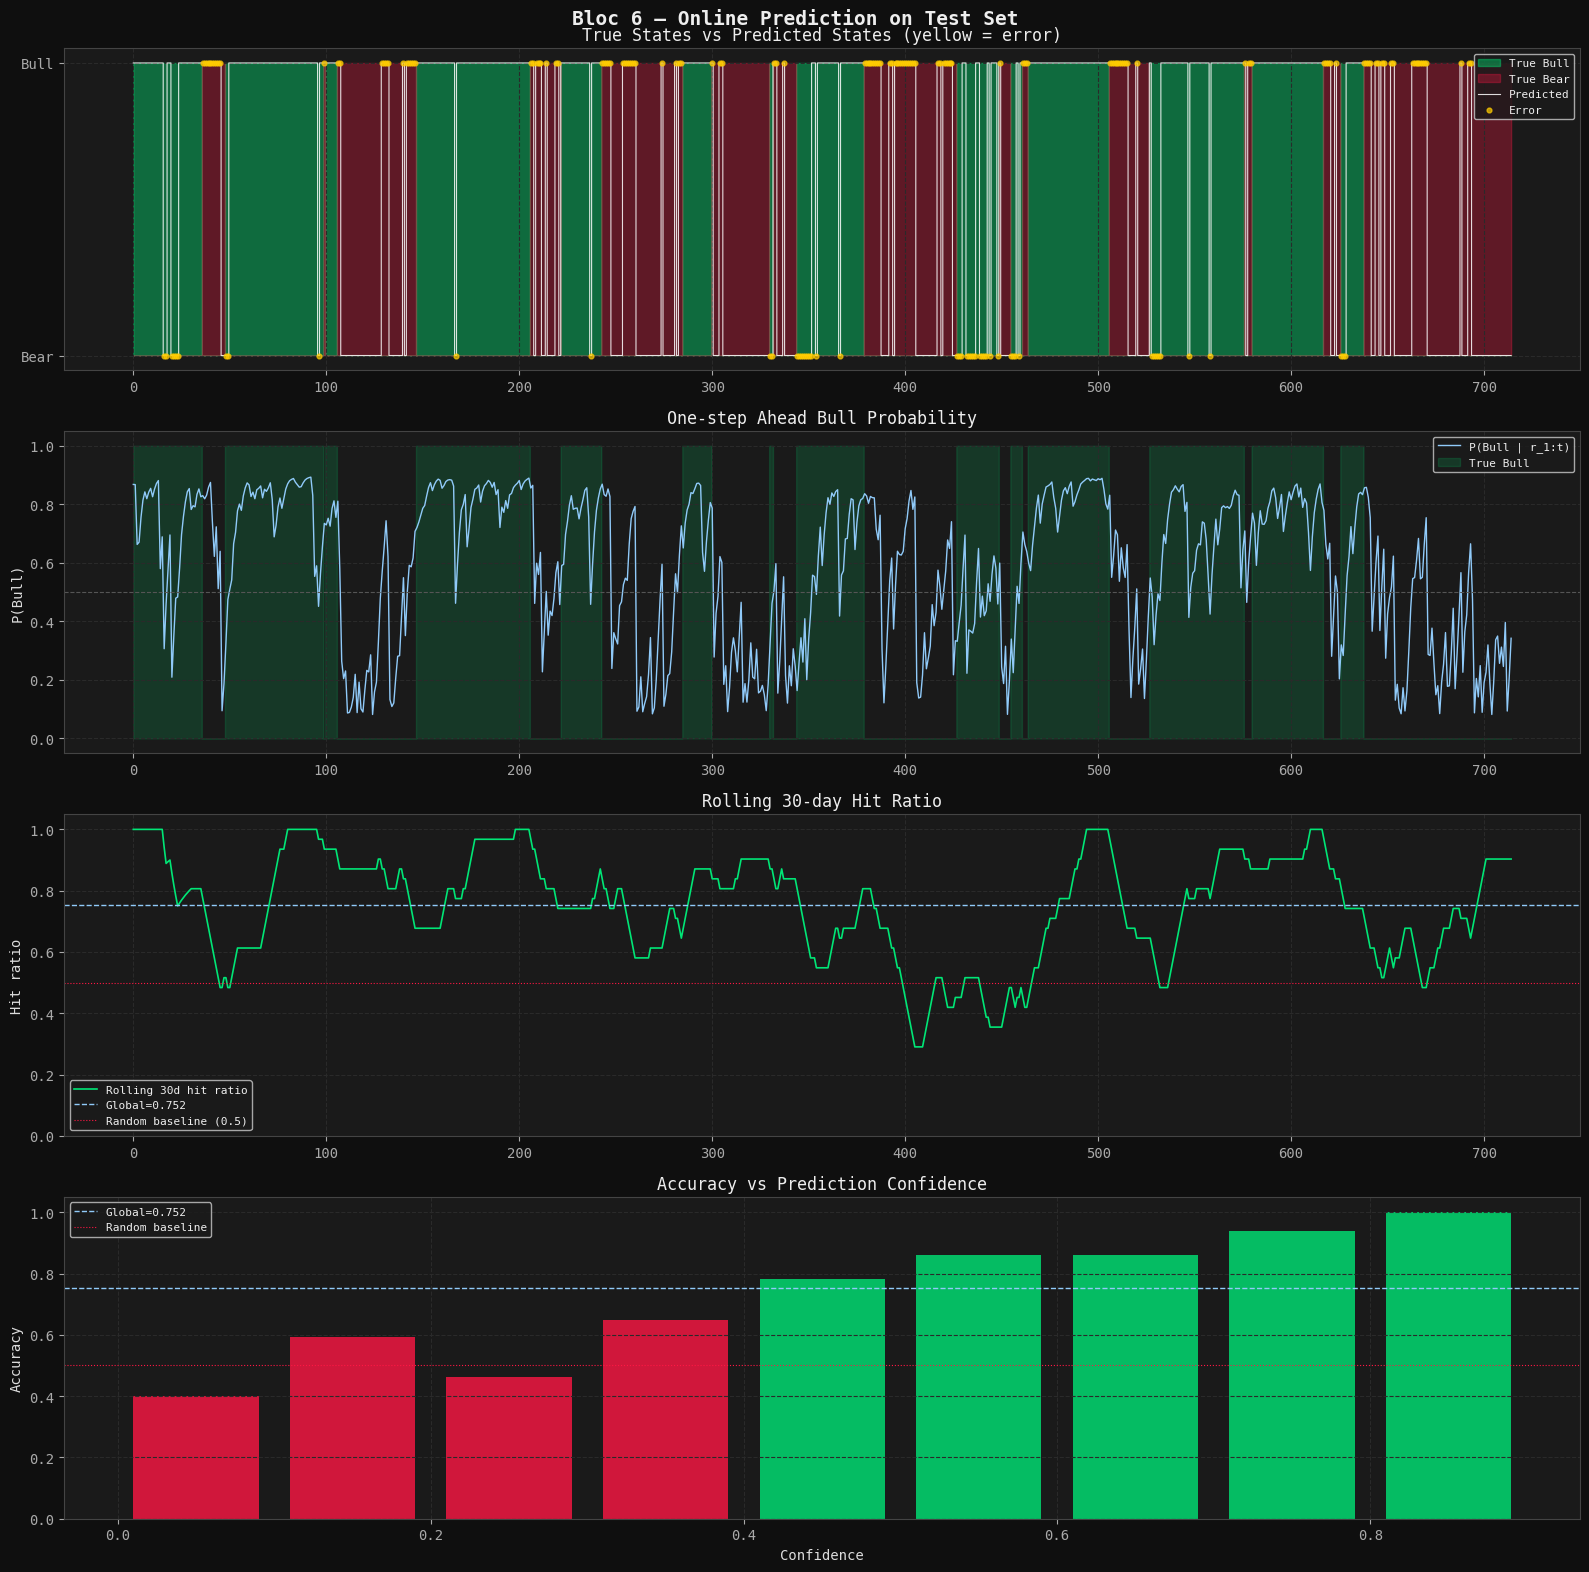


✅ Predictions stored.
   Global hit ratio : 0.7524 (75.2%)
   Precision        : 0.7308
   F1 score         : 0.7944


In [7]:
# ============================================================
# BLOCK 6 — Online Prediction t → t+1 (Test Set)
# ============================================================
# For each t in [T, 2T-1]:
#   1. We have the forward variable alpha_t = P(s_t | r_1:t)
#   2. We predict the state at t+1:
#      P(s_{t+1} = k | r_1:t) = sum_j P(s_{t+1}=k | s_t=j) * P(s_t=j | r_1:t)
#      i.e. one-step ahead prediction via matrix multiplication
#   3. We observe r_{t+1}, update alpha_{t+1} via Bayes
#   4. We compare predicted state to true state s_{t+1}
#
# This is a CAUSAL / ONLINE procedure — no future data is used.
# ============================================================

# ── 6.1  One-step ahead prediction ───────────────────────────
def predict_next_state(alpha_t, A):
    """
    Given log forward variable alpha_t and transition matrix A,
    return:
        pred_prob   : P(s_{t+1} = k | r_1:t)  shape (K,)
        pred_state  : argmax of pred_prob
    """
    # P(s_{t+1} = k | r_1:t) = sum_j A[j,k] * P(s_t=j | r_1:t)
    # In log-space: logsumexp(alpha_t + log A[:, k])
    log_A      = np.log(A + 1e-300)
    log_pred   = np.array([
        logsumexp(alpha_t + log_A[:, k])
        for k in range(A.shape[0])
    ])
    # Normalize to probabilities
    log_pred  -= logsumexp(log_pred)
    pred_prob  = np.exp(log_pred)
    pred_state = np.argmax(pred_prob)
    return pred_prob, pred_state, log_pred


def update_forward(log_pred, r_new, mu, sigma):
    """
    Update forward variable after observing r_{t+1}.
    alpha_{t+1} = log_pred + log_emission(r_{t+1})
    Normalized to avoid underflow.
    """
    log_b      = np.array([
        stats.norm.logpdf(r_new, loc=mu[k], scale=sigma[k])
        for k in range(len(mu))
    ])
    alpha_new  = log_pred + log_b
    alpha_new -= logsumexp(alpha_new)   # normalize
    return alpha_new


# ── 6.2  Online prediction loop ──────────────────────────────
print("Running online prediction on test set (t = T → 2T-1)...")

mu_c, sig_c, A_c = calibrated["mu"], calibrated["sigma"], calibrated["A"]

# Initialize with forward variable at t = T
alpha_t = inference["alpha_at_T"].copy()

# Storage
pred_states  = np.zeros(T, dtype=int)      # predicted state at t+1
pred_probs   = np.zeros((T, 2))            # P(s_{t+1}=k | r_1:t)
true_states  = s_test.copy()               # ground truth

for t in range(T):
    # Step 1: Predict s_{t+1} from current alpha_t
    pred_prob, pred_state, log_pred = predict_next_state(alpha_t, A_c)

    pred_states[t] = pred_state
    pred_probs[t]  = pred_prob

    # Step 2: Observe r_{t+1} and update alpha
    if t < T - 1:
        alpha_t = update_forward(log_pred, r_test[t], mu_c, sig_c)

print(f"  Prediction loop complete : {T} steps")

# ── 6.3  Global performance metrics ──────────────────────────
correct    = (pred_states == true_states)
hit_ratio  = correct.mean()

cm_test    = confusion_matrix_2x2(true_states, pred_states)
precision  = cm_test[1,1] / (cm_test[1,1] + cm_test[0,1] + 1e-9)
recall     = cm_test[1,1] / (cm_test[1,1] + cm_test[1,0] + 1e-9)
f1         = 2 * precision * recall / (precision + recall + 1e-9)
specificity = cm_test[0,0] / (cm_test[0,0] + cm_test[0,1] + 1e-9)

print(f"\n── Test set performance ──")
print(f"  Hit ratio   : {hit_ratio:.4f} ({100*hit_ratio:.1f}%)")
print(f"  Precision   : {precision:.4f}")
print(f"  Recall      : {recall:.4f}")
print(f"  F1 score    : {f1:.4f}")
print(f"  Specificity : {specificity:.4f}")
print(f"\n── Confusion matrix (Test) ──")
print(f"  TN={cm_test[0,0]}  FP={cm_test[0,1]}")
print(f"  FN={cm_test[1,0]}  TP={cm_test[1,1]}")

# ── 6.4  Rolling hit ratio ────────────────────────────────────
WINDOW_ROLL = 30
rolling_hit = np.array([
    correct[max(0, t-WINDOW_ROLL):t+1].mean()
    for t in range(len(correct))
])

# ── 6.5  Prediction confidence ────────────────────────────────
# confidence = |P(Bull) - 0.5| * 2  ∈ [0, 1]
confidence = np.abs(pred_probs[:, 1] - 0.5) * 2

# Accuracy binned by confidence
n_bins     = 10
conf_bins  = np.linspace(0, 1, n_bins + 1)
bin_acc    = []
bin_counts = []
for i in range(n_bins):
    mask = (confidence >= conf_bins[i]) & (confidence < conf_bins[i+1])
    if mask.sum() > 0:
        bin_acc.append(correct[mask].mean())
        bin_counts.append(mask.sum())
    else:
        bin_acc.append(np.nan)
        bin_counts.append(0)

bin_centers = (conf_bins[:-1] + conf_bins[1:]) / 2

print(f"\n── Accuracy by confidence bin ──")
for i in range(n_bins):
    if bin_counts[i] > 0:
        print(f"  [{conf_bins[i]:.1f} – {conf_bins[i+1]:.1f}]  "
              f"acc={bin_acc[i]:.3f}  n={bin_counts[i]}")

# ── 6.6  Visualization ────────────────────────────────────────
fig, axes = plt.subplots(4, 1, figsize=(16, 16), sharex=False)
fig.suptitle("Block 6 — Online Prediction on Test Set", fontsize=14, fontweight="bold")

t_axis = np.arange(T)

# Panel 1: True vs predicted states
axes[0].fill_between(t_axis, true_states,       step="mid",
                     color=BULL_COLOR,  alpha=0.4, label="True Bull")
axes[0].fill_between(t_axis, 1-true_states,     step="mid",
                     color=BEAR_COLOR,  alpha=0.3, label="True Bear")
axes[0].step(t_axis, pred_states, color="white",
             lw=0.8, alpha=0.85, where="mid", label="Predicted")
# Mark errors
errors = ~correct
axes[0].scatter(t_axis[errors], pred_states[errors],
                color="#ffcc00", s=12, zorder=5, label="Error", alpha=0.7)
axes[0].set_yticks([0, 1])
axes[0].set_yticklabels(["Bear", "Bull"])
axes[0].set_title("True States vs Predicted States (yellow = error)")
axes[0].legend(fontsize=8, loc="upper right")

# Panel 2: P(Bull) over time
axes[1].plot(t_axis, pred_probs[:, 1],
             color=NEUTRAL_COLOR, lw=1.0, label="P(Bull | r_1:t)")
axes[1].axhline(0.5, color="#555", lw=0.8, ls="--")
axes[1].fill_between(t_axis, true_states, alpha=0.15,
                     color=BULL_COLOR, step="mid", label="True Bull")
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_ylabel("P(Bull)")
axes[1].set_title("One-step Ahead Bull Probability")
axes[1].legend(fontsize=8)

# Panel 3: Rolling hit ratio
axes[2].plot(t_axis, rolling_hit,
             color=BULL_COLOR, lw=1.2, label=f"Rolling {WINDOW_ROLL}d hit ratio")
axes[2].axhline(hit_ratio, color=NEUTRAL_COLOR,
                lw=1.0, ls="--", label=f"Global={hit_ratio:.3f}")
axes[2].axhline(0.5, color=BEAR_COLOR,
                lw=0.8, ls=":", label="Random baseline (0.5)")
axes[2].set_ylim(0, 1.05)
axes[2].set_ylabel("Hit ratio")
axes[2].set_title(f"Rolling {WINDOW_ROLL}-day Hit Ratio")
axes[2].legend(fontsize=8)

# Panel 4: Accuracy by confidence bin
valid = [i for i in range(n_bins) if not np.isnan(bin_acc[i])]
axes[3].bar([bin_centers[i] for i in valid],
            [bin_acc[i] for i in valid],
            width=0.08,
            color=[BULL_COLOR if bin_acc[i] >= hit_ratio
                   else BEAR_COLOR for i in valid],
            alpha=0.8)
axes[3].axhline(hit_ratio, color=NEUTRAL_COLOR,
                lw=1.0, ls="--", label=f"Global={hit_ratio:.3f}")
axes[3].axhline(0.5, color=BEAR_COLOR,
                lw=0.8, ls=":", label="Random baseline")
axes[3].set_xlabel("Confidence")
axes[3].set_ylabel("Accuracy")
axes[3].set_title("Accuracy vs Prediction Confidence")
axes[3].legend(fontsize=8)

plt.tight_layout()
plt.show()

# ── 6.7  Store prediction results ────────────────────────────
predictions = {
    "pred_states"  : pred_states,
    "pred_probs"   : pred_probs,
    "true_states"  : true_states,
    "correct"      : correct,
    "confidence"   : confidence,
    "hit_ratio"    : hit_ratio,
    "precision"    : precision,
    "recall"       : recall,
    "f1"           : f1,
    "rolling_hit"  : rolling_hit,
}

print(f"\n✅ Predictions stored.")
print(f"   Global hit ratio : {hit_ratio:.4f} ({100*hit_ratio:.1f}%)")
print(f"   Precision        : {precision:.4f}")
print(f"   F1 score         : {f1:.4f}")

**Out-of-sample state prediction (715 days).** Accuracy 75.2%, precision 0.73, recall 0.87, specificity 0.61. Bull days are 55% of the test set, so always predicting "bull" would score 55%: the filter adds about 20 points. Accuracy rises with the model's confidence (from 40–60% in the lowest-confidence bins to 94–100% in the highest).

Two caveats: the model is evaluated on data generated by (almost) the same model family it fits, so this is an upper bound for real data; and predicting the **state** is not predicting the **sign of the return**. With |μ|/σ ≈ 0.05, even a perfectly known state gives a directional edge of about 2 percentage points.

── SNR statistics ──
  Mean SNR  : 0.03737
  Std SNR   : 0.01234
  Min SNR   : 0.01553
  Max SNR   : 0.05454
  Median SNR: 0.03897

── Hit ratio by SNR decile ──
       SNR bin   Hit ratio   Precision       N
       0.01734      0.9861      0.0000      72
       0.02134      0.8873      0.0000      71
       0.02634      0.6389      0.0000      72
       0.03169      0.4366      0.3846      71
       0.03660      0.4507      0.4507      71
       0.04144      0.6667      0.6667      72
       0.04579      0.8169      0.8169      71
       0.04892      0.7917      0.7917      72
       0.05116      0.8873      0.8873      71
       0.05335      0.9583      0.9583      72

── SNR vs correctness correlation ──
  Spearman ρ = 0.0728  (p=5.1569e-02)
  Pearson  r = 0.0420  (p=2.6161e-01)

── SNR threshold → hit ratio tradeoff ──
     Threshold   Hit ratio    Coverage
       0.01553      0.7524       1.000
       0.02103      0.7166       0.849
       0.02917      0.7160       0.699
       0.

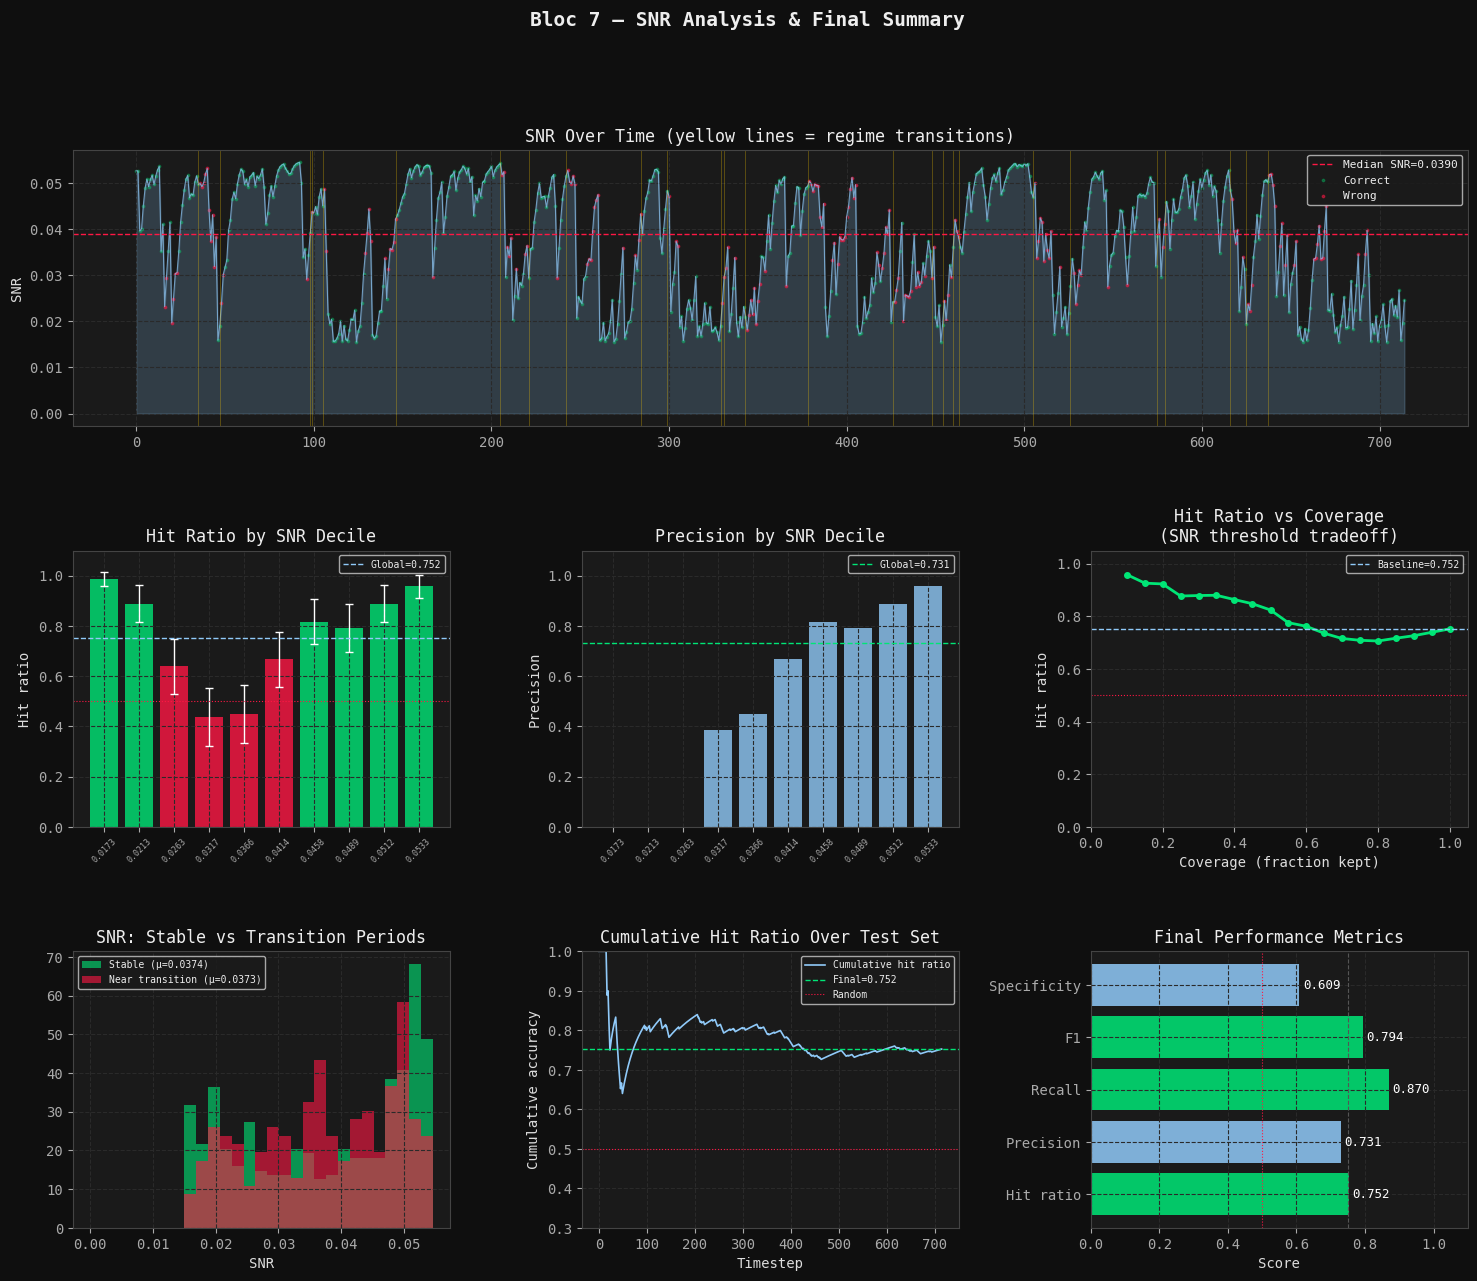


✅ Block 7 complete. Figure saved to nft_hmm_results.png


In [8]:
# ============================================================
# BLOCK 7 — Success Rate vs Signal-to-Noise Ratio (SNR)
# ============================================================
# The SNR measures how strong the model's prediction signal is
# relative to the noise in the observations.
#
# We define SNR at each timestep t as:
#   SNR_t = |μ_pred_t| / σ_pred_t
# where:
#   μ_pred_t = expected return under predicted state
#            = P(Bull_t) * μ_bull + P(Bear_t) * μ_bear
#   σ_pred_t = expected volatility under predicted state
#            = P(Bull_t) * σ_bull + P(Bear_t) * σ_bear
#
# High SNR → model is confident AND the signal is strong
# We then bin timesteps by SNR and check hit ratio per bin.
# ============================================================

# ── 7.1  Compute SNR at each timestep ────────────────────────
mu_c   = calibrated["mu"]
sig_c  = calibrated["sigma"]

# Expected return and volatility under the predictive distribution
mu_pred    = (pred_probs[:, 0] * mu_c[0] +
              pred_probs[:, 1] * mu_c[1])

sigma_pred = (pred_probs[:, 0] * sig_c[0] +
              pred_probs[:, 1] * sig_c[1])

# SNR = |signal| / noise
snr = np.abs(mu_pred) / (sigma_pred + 1e-8)

print("── SNR statistics ──")
print(f"  Mean SNR  : {snr.mean():.5f}")
print(f"  Std SNR   : {snr.std():.5f}")
print(f"  Min SNR   : {snr.min():.5f}")
print(f"  Max SNR   : {snr.max():.5f}")
print(f"  Median SNR: {np.median(snr):.5f}")

# ── 7.2  Hit ratio vs SNR (binned) ───────────────────────────
N_BINS_SNR  = 10
snr_sorted  = np.sort(snr)
snr_bins    = np.percentile(snr, np.linspace(0, 100, N_BINS_SNR + 1))
snr_bins    = np.unique(snr_bins)   # remove duplicates
n_bins_actual = len(snr_bins) - 1

bin_snr_mid  = []
bin_snr_hit  = []
bin_snr_n    = []
bin_snr_prec = []
bin_snr_std  = []

for i in range(n_bins_actual):
    mask = (snr >= snr_bins[i]) & (snr < snr_bins[i+1])
    if i == n_bins_actual - 1:
        mask = (snr >= snr_bins[i])   # include last edge

    if mask.sum() > 0:
        bin_snr_mid.append((snr_bins[i] + snr_bins[i+1]) / 2)
        bin_snr_hit.append(correct[mask].mean())
        bin_snr_n.append(mask.sum())

        # Precision within bin
        tp = ((true_states[mask] == 1) & (pred_states[mask] == 1)).sum()
        fp = ((true_states[mask] == 0) & (pred_states[mask] == 1)).sum()
        bin_snr_prec.append(tp / (tp + fp + 1e-9))
        bin_snr_std.append(correct[mask].std() /
                           np.sqrt(mask.sum()))   # standard error

bin_snr_mid  = np.array(bin_snr_mid)
bin_snr_hit  = np.array(bin_snr_hit)
bin_snr_n    = np.array(bin_snr_n)
bin_snr_prec = np.array(bin_snr_prec)
bin_snr_std  = np.array(bin_snr_std)

print(f"\n── Hit ratio by SNR decile ──")
print(f"  {'SNR bin':>12}  {'Hit ratio':>10}  {'Precision':>10}  {'N':>6}")
for i in range(len(bin_snr_mid)):
    print(f"  {bin_snr_mid[i]:>12.5f}  "
          f"{bin_snr_hit[i]:>10.4f}  "
          f"{bin_snr_prec[i]:>10.4f}  "
          f"{bin_snr_n[i]:>6}")

# ── 7.3  Spearman correlation SNR vs correctness ─────────────
from scipy.stats import spearmanr, pearsonr
rho_spearman, p_spearman = spearmanr(snr, correct.astype(float))
rho_pearson,  p_pearson  = pearsonr( snr, correct.astype(float))

print(f"\n── SNR vs correctness correlation ──")
print(f"  Spearman ρ = {rho_spearman:.4f}  (p={p_spearman:.4e})")
print(f"  Pearson  r = {rho_pearson:.4f}  (p={p_pearson:.4e})")

# ── 7.4  SNR threshold analysis ──────────────────────────────
# What happens if we only trade/predict when SNR > threshold?
thresholds   = np.percentile(snr, np.linspace(0, 90, 19))
thresh_hit   = []
thresh_cov   = []   # coverage = fraction of timesteps kept

for thr in thresholds:
    mask = snr >= thr
    if mask.sum() > 0:
        thresh_hit.append(correct[mask].mean())
        thresh_cov.append(mask.mean())
    else:
        thresh_hit.append(np.nan)
        thresh_cov.append(0.0)

thresh_hit = np.array(thresh_hit)
thresh_cov = np.array(thresh_cov)

print(f"\n── SNR threshold → hit ratio tradeoff ──")
print(f"  {'Threshold':>12}  {'Hit ratio':>10}  {'Coverage':>10}")
for i in range(0, len(thresholds), 3):
    print(f"  {thresholds[i]:>12.5f}  "
          f"{thresh_hit[i]:>10.4f}  "
          f"{thresh_cov[i]:>10.3f}")

# ── 7.5  Regime transition analysis ──────────────────────────
# SNR tends to drop near regime transitions
# Identify transition points and check SNR around them

transitions = np.where(np.diff(true_states) != 0)[0]
print(f"\n── Regime transitions in test set : {len(transitions)} ──")

# SNR around transitions (window of ±5 days)
WINDOW_TRANS = 5
snr_near_transition  = []
snr_stable           = []

for t in range(len(snr)):
    near = any(abs(t - tr) <= WINDOW_TRANS for tr in transitions)
    if near:
        snr_near_transition.append(snr[t])
    else:
        snr_stable.append(snr[t])

snr_near_transition = np.array(snr_near_transition)
snr_stable          = np.array(snr_stable)

print(f"  Avg SNR near transitions  : {snr_near_transition.mean():.5f}")
print(f"  Avg SNR in stable regimes : {snr_stable.mean():.5f}")
print(f"  Ratio (stable/transition) : "
      f"{snr_stable.mean()/snr_near_transition.mean():.3f}x")

# ── 7.6  Full summary table ───────────────────────────────────
print(f"\n{'='*55}")
print(f"  FINAL SUMMARY")
print(f"{'='*55}")
print(f"  Training set accuracy")
print(f"    Filtered          : {acc_filtered:.4f} ({100*acc_filtered:.1f}%)")
print(f"    Smoothed          : {acc_smoothed:.4f} ({100*acc_smoothed:.1f}%)")
print(f"    Viterbi           : {acc_viterbi:.4f}  ({100*acc_viterbi:.1f}%)")
print(f"\n  Test set (online prediction)")
print(f"    Hit ratio         : {hit_ratio:.4f} ({100*hit_ratio:.1f}%)")
print(f"    Precision         : {precision:.4f}")
print(f"    Recall            : {recall:.4f}")
print(f"    F1 score          : {f1:.4f}")
print(f"    Specificity       : {specificity:.4f}")
print(f"\n  SNR analysis")
print(f"    Spearman ρ        : {rho_spearman:.4f} (p={p_spearman:.2e})")
print(f"    SNR > median      : "
      f"{correct[snr >= np.median(snr)].mean():.4f} hit ratio")
print(f"    SNR < median      : "
      f"{correct[snr < np.median(snr)].mean():.4f} hit ratio")
print(f"{'='*55}")

# ── 7.7  Visualization ────────────────────────────────────────
fig = plt.figure(figsize=(18, 14))
fig.suptitle("Block 7 — SNR Analysis & Final Summary", 
             fontsize=14, fontweight="bold")

gs  = fig.add_gridspec(3, 3, hspace=0.45, wspace=0.35)
ax1 = fig.add_subplot(gs[0, :])     # SNR time series
ax2 = fig.add_subplot(gs[1, 0])     # Hit ratio vs SNR bin
ax3 = fig.add_subplot(gs[1, 1])     # Precision vs SNR bin
ax4 = fig.add_subplot(gs[1, 2])     # Coverage vs threshold
ax5 = fig.add_subplot(gs[2, 0])     # SNR near transitions
ax6 = fig.add_subplot(gs[2, 1])     # Cumulative hit ratio
ax7 = fig.add_subplot(gs[2, 2])     # Final metrics radar

# Panel 1: SNR over time
t_axis = np.arange(T)
ax1.plot(t_axis, snr, color=NEUTRAL_COLOR, lw=0.8, alpha=0.7)
ax1.fill_between(t_axis, snr, alpha=0.2, color=NEUTRAL_COLOR)
for tr in transitions:
    ax1.axvline(tr, color="#ffcc00", lw=0.5, alpha=0.4)
ax1.axhline(np.median(snr), color=BEAR_COLOR,
            lw=1.0, ls="--", label=f"Median SNR={np.median(snr):.4f}")
# Mark correct/wrong
ax1.scatter(t_axis[correct],  snr[correct],
            color=BULL_COLOR, s=3, alpha=0.3, label="Correct")
ax1.scatter(t_axis[~correct], snr[~correct],
            color=BEAR_COLOR, s=3, alpha=0.5, label="Wrong")
ax1.set_title("SNR Over Time (yellow lines = regime transitions)")
ax1.set_ylabel("SNR")
ax1.legend(fontsize=8)

# Panel 2: Hit ratio by SNR bin
bar_colors = [BULL_COLOR if h >= hit_ratio else BEAR_COLOR
              for h in bin_snr_hit]
ax2.bar(range(len(bin_snr_mid)), bin_snr_hit,
        color=bar_colors, alpha=0.8)
ax2.errorbar(range(len(bin_snr_mid)), bin_snr_hit,
             yerr=bin_snr_std * 1.96, fmt="none",
             color="white", capsize=3, lw=1)
ax2.axhline(hit_ratio, color=NEUTRAL_COLOR,
            lw=1.0, ls="--", label=f"Global={hit_ratio:.3f}")
ax2.axhline(0.5, color=BEAR_COLOR, lw=0.8, ls=":")
ax2.set_xticks(range(len(bin_snr_mid)))
ax2.set_xticklabels([f"{v:.4f}" for v in bin_snr_mid],
                    rotation=45, fontsize=6)
ax2.set_title("Hit Ratio by SNR Decile")
ax2.set_ylabel("Hit ratio")
ax2.legend(fontsize=7)
ax2.set_ylim(0, 1.1)

# Panel 3: Precision by SNR bin
ax3.bar(range(len(bin_snr_mid)), bin_snr_prec,
        color=NEUTRAL_COLOR, alpha=0.8)
ax3.axhline(precision, color=BULL_COLOR,
            lw=1.0, ls="--", label=f"Global={precision:.3f}")
ax3.set_xticks(range(len(bin_snr_mid)))
ax3.set_xticklabels([f"{v:.4f}" for v in bin_snr_mid],
                    rotation=45, fontsize=6)
ax3.set_title("Precision by SNR Decile")
ax3.set_ylabel("Precision")
ax3.legend(fontsize=7)
ax3.set_ylim(0, 1.1)

# Panel 4: Hit ratio vs coverage tradeoff
ax4.plot(thresh_cov, thresh_hit,
         color=BULL_COLOR, lw=2, marker="o", markersize=4)
ax4.axhline(hit_ratio, color=NEUTRAL_COLOR,
            lw=1.0, ls="--", label=f"Baseline={hit_ratio:.3f}")
ax4.axhline(0.5, color=BEAR_COLOR, lw=0.8, ls=":")
ax4.set_xlabel("Coverage (fraction kept)")
ax4.set_ylabel("Hit ratio")
ax4.set_title("Hit Ratio vs Coverage\n(SNR threshold tradeoff)")
ax4.legend(fontsize=7)
ax4.set_xlim(0, 1.05)
ax4.set_ylim(0, 1.05)

# Panel 5: SNR distribution near vs away from transitions
bins_hist = np.linspace(0, snr.max(), 30)
ax5.hist(snr_stable,          bins=bins_hist, color=BULL_COLOR,
         alpha=0.6, density=True, label=f"Stable (μ={snr_stable.mean():.4f})")
ax5.hist(snr_near_transition, bins=bins_hist, color=BEAR_COLOR,
         alpha=0.6, density=True,
         label=f"Near transition (μ={snr_near_transition.mean():.4f})")
ax5.set_title("SNR: Stable vs Transition Periods")
ax5.set_xlabel("SNR")
ax5.legend(fontsize=7)

# Panel 6: Cumulative hit ratio over test set
cum_correct = np.cumsum(correct) / (np.arange(T) + 1)
ax6.plot(t_axis, cum_correct,
         color=NEUTRAL_COLOR, lw=1.2, label="Cumulative hit ratio")
ax6.axhline(hit_ratio, color=BULL_COLOR,
            lw=1.0, ls="--", label=f"Final={hit_ratio:.3f}")
ax6.axhline(0.5, color=BEAR_COLOR, lw=0.8, ls=":", label="Random")
ax6.set_title("Cumulative Hit Ratio Over Test Set")
ax6.set_xlabel("Timestep")
ax6.set_ylabel("Cumulative accuracy")
ax6.legend(fontsize=7)
ax6.set_ylim(0.3, 1.0)

# Panel 7: Final metrics bar chart
metrics_names  = ["Hit ratio", "Precision", "Recall", "F1", "Specificity"]
metrics_values = [hit_ratio, precision, recall, f1, specificity]
colors_bar     = [BULL_COLOR if v >= 0.75 else NEUTRAL_COLOR
                  if v >= 0.6 else BEAR_COLOR for v in metrics_values]
bars = ax7.barh(metrics_names, metrics_values,
                color=colors_bar, alpha=0.85)
ax7.axvline(0.5, color=BEAR_COLOR, lw=0.8, ls=":")
ax7.axvline(0.75, color="#555", lw=0.8, ls="--")
for bar, val in zip(bars, metrics_values):
    ax7.text(val + 0.01, bar.get_y() + bar.get_height()/2,
             f"{val:.3f}", va="center", fontsize=9, color="white")
ax7.set_xlim(0, 1.1)
ax7.set_title("Final Performance Metrics")
ax7.set_xlabel("Score")

plt.savefig("nft_hmm_results.png", dpi=150,
            bbox_inches="tight", facecolor="#0f0f0f")
plt.show()

print("\n✅ Block 7 complete. Figure saved to nft_hmm_results.png")

**Confidence filter.** Restricting to the 10% of days with the highest predicted signal-to-noise ratio raises accuracy to 95.8%, and to 82% above the median. The overall relation is weak, though (Spearman ρ = 0.07, p = 0.05), and the lowest-SNR deciles are also very accurate (they are confident *bear* calls), so the SNR is not a clean reliability score. A threshold chosen on the test set would also need to be validated on separate data.

## Part B · Agent-based state-space model on real data

The modified Chiarella model of notebook 01 (the team called this part "Majewski-inspired", after Majewski, Ciliberti & Bouchaud's calibration of trend-following/fundamentalist models) is used as a forecasting model:

1. **Calibrate** $\xi = (\kappa, \beta, \gamma, \alpha, \lambda, \sigma_N)$ by SMM on a 365-day window of real returns (same six moments as notebook 01, differential evolution + iterative optimal weighting);
2. **Filter** the latent state $(p_t, m_t, v_t)$ with a SIR particle filter (2,000 particles, systematic resampling);
3. **Forecast** the next 30 daily returns by 1,000 Monte-Carlo paths from the filtered state;
4. **Roll** the window forward by 30 days (35 windows) and score each forecast against the realised returns.

In [2]:

@njit(cache=True)
def chiara_model(epsilon, kappa, beta, gamma, alpha, lmbda, sigma_N):
    NIT = len(epsilon)
    v = np.zeros(NIT)
    m = np.zeros(NIT)
    p = np.zeros(NIT)

    for t in range(1, NIT - 1):
        v[t] = (1 - lmbda) * v[t - 1] + lmbda * p[t]
        m[t] = (1 - alpha) * m[t - 1] + alpha * (p[t] - p[t - 1])
        p[t + 1] = (
            p[t]
            + kappa * ((v[t] - p[t]) ** 3 - (v[t - 1] - p[t - 1]) ** 3)
            + beta  * (np.tanh(gamma * m[t]) - np.tanh(gamma * m[t - 1]))
            + sigma_N * epsilon[t]   # ← scaling ici, epsilon ~ N(0,1)
        )

    returns = np.diff(p)
    return p, returns

In [3]:
@njit(cache=True)
def _kurtosis(r):
    mu  = np.mean(r)
    std = np.std(r)
    if std == 0.0:
        return 0.0
    return np.mean(((r - mu) / std) ** 4) - 3.0

@njit(cache=True)
def _skew(r):
    mu  = np.mean(r)
    std = np.std(r)
    if std == 0.0:
        return 0.0
    return np.mean(((r - mu) / std) ** 3)

@njit(cache=True)
def _corrcoef(x, y):
    mx, my = np.mean(x), np.mean(y)
    num    = np.mean((x - mx) * (y - my))
    denom  = np.std(x) * np.std(y)
    if denom == 0.0:
        return 0.0
    return num / denom

@njit(cache=True)
def _quantile(arr, q):
    sorted_arr = np.sort(arr)
    idx = q * (len(sorted_arr) - 1)
    lo  = int(idx)
    hi  = lo + 1
    if hi >= len(sorted_arr):
        return sorted_arr[lo]
    frac = idx - lo
    return sorted_arr[lo] * (1 - frac) + sorted_arr[hi] * frac

@njit(cache=True)
def compute_moments(r):
    return np.array([
        np.var(r),
        _kurtosis(r),
        _quantile(np.abs(r), 0.99),
        _corrcoef(r[:-1], r[1:]),
        _corrcoef(r[:-1] ** 2, r[1:] ** 2),
        _skew(r),
    ])

In [10]:
def warmup_numba():
    print("Compiling Numba functions...")
    eps_test = np.random.normal(0, 1, 100)
    _p, _r   = chiara_model(eps_test, 0.05, 0.1, 1.0, 0.1, 0.05, 0.01)
    compute_moments(_r)
    print("Compilation done.")

warmup_numba()

Compiling Numba functions...
Compilation done.


In [ ]:
# ============================================================
# BLOCK 2 — Target series + target moments + global settings
# ============================================================
# Extract the log-price series from daily_signals,
# define the windows T and tau, and compute the
# target moments on the first calibration window.
#
# The model is calibrated on log-returns because:
#   - chiara_model produces price increments
#   - the moments (variance, kurtosis, skew, autocorr)
#     are defined on returns, not on levels
# ============================================================

# ── 2.1  Extract the series ──────────────────────────────
log_price   = daily_signals["log_price"].to_numpy()
log_returns = daily_signals["log_return"].to_numpy()
dates       = daily_signals["date"].to_numpy()

N = len(log_returns)
print(f"Available series    : {N} log-returns")
print(f"Start date          : {dates[0]}")
print(f"End date            : {dates[-1]}")

# ── 2.2  Walk-forward settings ──────────
T   = 365    # calibration window (1 year)
TAU = 30     # step between windows (1 month)
TC  = 0.003  # transaction costs crypto (0.3%)

n_windows = (N - T) // TAU
print(f"\nCalibration window  : T   = {T} days")
print(f"Step                : TAU = {TAU} days")
print(f"Number of windows   : {n_windows}")
print(f"Test coverage       : {n_windows * TAU} days "
      f"({100 * n_windows * TAU / N:.1f}% of the series)")

# ── 2.3  Target moments on the first window ──────────────
# moments_cible is a GLOBAL variable used by distance()
r_first_window = log_returns[:T]
moments_cible  = compute_moments(r_first_window)

MOMENT_NAMES = [
    "Variance",
    "Kurtosis (excess)",
    "99th percentile |r|",
    "Autocorr r(t) r(t-1)",
    "Autocorr r²(t) r²(t-1)",
    "Skewness",
]

print(f"\n── Target moments (window 0 → T={T}) ──")
for name, val in zip(MOMENT_NAMES, moments_cible):
    print(f"  {name:<30} : {val:.6f}")

# ── 2.4  Sanity check: consistency with the HMM part ──
print(f"\n── Sanity check ──")
print(f"  std(r)    = {np.std(r_first_window):.4f}  "
      f"(expected ~0.50 from Block 1)")
print(f"  skew(r)   = {stats.skew(r_first_window):.4f}  "
      f"(attendu ~-0.99)")
print(f"  kurt(r)   = {stats.kurtosis(r_first_window):.4f}  "
      f"(attendu ~8.27)")

# ── 2.5  Plot the series ───────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=False)
fig.suptitle("Block 2 — NFT market target series",
             fontsize=13, fontweight="bold")

# Panel 1: log-price with walk-forward windows
axes[0].plot(dates, log_price, color=NEUTRAL_COLOR, lw=1.0)
for i in range(min(n_windows, 20)):    # show the first 20 windows
    start = i * TAU
    end   = start + T
    axes[0].axvspan(dates[start], dates[min(end, N-1)],
                    alpha=0.04, color=BULL_COLOR)
axes[0].axvspan(dates[0], dates[T-1],
                alpha=0.15, color="#ffcc00", label=f"Window 0 (T={T}d)")
axes[0].set_ylabel("log(USD price)")
axes[0].set_title("Log-price with walk-forward windows (yellow = window 0)")
axes[0].legend(fontsize=8)

# Panel 2 : log-returns
axes[1].plot(dates, log_returns, color=NEUTRAL_COLOR, lw=0.7, alpha=0.8)
axes[1].axhline(0, color="#555", lw=0.6)
axes[1].axvspan(dates[0], dates[T-1], alpha=0.1, color="#ffcc00")
axes[1].set_ylabel("Log-return")
axes[1].set_title("Log-returns journaliers")

# Panel 3: return distribution on window 0
r_plot  = r_first_window
x_range = np.linspace(r_plot.min(), r_plot.max(), 200)
axes[2].hist(r_plot, bins=40, density=True,
             color=NEUTRAL_COLOR, alpha=0.6, label="Empirique")
axes[2].plot(x_range,
             stats.norm.pdf(x_range, r_plot.mean(), r_plot.std()),
             color=BULL_COLOR, lw=1.5, label="Gaussienne fit")
axes[2].set_xlabel("Log-return")
axes[2].set_ylabel("Density")
axes[2].set_title(f"Return distribution — window 0 (T={T} days)")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

# ── 2.6  Store for the next blocks ─────────────────────
STEP = (N - T) // (n_windows - 1) if n_windows > 1 else TAU
series = {
    "log_price"   : log_price,
    "log_returns" : log_returns,
    "dates"       : dates,
    "N"           : N,
    "T"           : T,
    "TAU"         : TAU,
    "TC"          : TC,
    "step"        : STEP,        # ← ajouter
    "n_windows"   : n_windows,
}

print(f"\n✅ Series stored in `series`.")
print(f"   {n_windows} windows × {TAU} days = "
      f"{n_windows * TAU} days of forecasts")
print(f"   moments_cible initialised on window 0 → T={T}")
print(f"\n→ Ready for Block 3 (SMM calibration on window 0)")

**Calibration settings.** A first attempt with the bounds of notebook 01 failed: $\sigma_N$ stuck at its upper bound 0.1 while the real daily volatility is 0.50, and the simulated paths were longer than the 365-day window. The cell below widens the noise bound to 1.0, aligns the simulation length with the window and switches to differential evolution. †

In [ ]:
# ============================================================
# BLOCK 3B — Wider bounds + sigma_N rescaling
# ============================================================
# Problem: upper bound 0.1 on sigma_N is too small
# std(log_returns NFT) ≈ 0.50 → sigma_N doit pouvoir atteindre ~0.5
#
# Second problem: NIT_SIM = 1000 but T = 365
# Align NIT_SIM with T so that simulated moments
# are comparable with empirical moments.
# ============================================================

# ── 3B.1  Quick check ───────────────────────────────────
r_win0 = series["log_returns"][:series["T"]]

print("── NFT series check ──")
print(f"  std(r)        = {np.std(r_win0):.4f}")
print(f"  variance(r)   = {np.var(r_win0):.4f}")
print(f"  required sigma_N ≈ {np.std(r_win0):.4f}  "
      f"(current upper bound = 0.1 → too small)")

# ── 3B.2  New bounds ────────────────────────────────────
bounds_v2 = [
    (0.001, 0.5),    # kappa
    (0.001, 0.5),    # beta
    (0.1,   10.0),   # gamma
    (0.01,  0.5),    # alpha
    (0.01,  0.5),    # lmbda
    (0.01,  1.0),    # sigma_N  ← widened to 1.0
]

# ── 3B.3  New calibration settings ──────────────────
CALIB_PARAMS_V2 = {
    "NIT_SIM"  : T,      # aligned with T=365 so moments are comparable
    "N_SIM"    : 10,
    "N_RUNS"   : 50,
    "MAXITER"  : 50,
    "POPSIZE"  : 15,
    "TOL"      : 0.01,
    "GMM_ITER" : 3,
}

print(f"\n── New settings ──")
print(f"  NIT_SIM  : {CALIB_PARAMS_V2['NIT_SIM']}  "
      f"(was 1000, aligned with T)")
print(f"  sigma_N  : bornes [{bounds_v2[5][0]}, {bounds_v2[5][1]}]  "
      f"(was [0.001, 0.1])")

# ── 3B.4  Distance function v2 ────────────────────────────────
def distance_v2(x, W, moments_target, cp):
    kappa, beta, gamma, alpha, lmbda, sigma_N = x
    moments_list = np.empty((cp["N_SIM"], 6))
    for i in range(cp["N_SIM"]):
        eps             = np.random.normal(0, 1, cp["NIT_SIM"])
        _p, r           = chiara_model(eps, kappa, beta, gamma,
                                        alpha, lmbda, sigma_N)
        if len(r) < 2:
            moments_list[i] = np.zeros(6)
            continue
        moments_list[i] = compute_moments(r)
    moments_sim = np.mean(moments_list, axis=0)
    diff        = moments_sim - moments_target
    return float(diff @ W @ diff)


# ── 3B.5  calibrate v2 ───────────────────────────────
def calibrate_v2(r_window, cp=CALIB_PARAMS_V2,
                 bnds=bounds_v2, verbose=False, seed=0):
    """
    Calibrate the model with corrected bounds and NIT_SIM.
    """
    moments_target = compute_moments(r_window)
    W      = np.eye(6)
    xi_old = np.zeros(6)

    for iteration in range(cp["GMM_ITER"]):
        # Unique seed per window AND per GMM iteration
        de_seed = seed * 100 + iteration
        # Seed the global RNG: distance_v2 uses np.random.normal
        # (global RNG), not the one inside differential_evolution.
        # Without this line every window would reuse the same sequence.
        np.random.seed(de_seed)
        result = differential_evolution(
            distance_v2,
            bnds,
            args       = (W, moments_target, cp),
            maxiter    = cp["MAXITER"],
            seed       = de_seed,
            workers    = 1,
            updating   = "immediate",
            polish     = True,
            popsize    = cp["POPSIZE"],
            tol        = cp["TOL"],
        )
        xi_hat = result.x

        # Covariance matrix: private RNG per window/iteration
        rng_cov = np.random.default_rng(de_seed + 50000)
        moments_runs = np.empty((cp["N_RUNS"], 6))
        for k in range(cp["N_RUNS"]):
            eps               = rng_cov.standard_normal(cp["NIT_SIM"])
            _p, r             = chiara_model(eps, *xi_hat)
            moments_runs[k]   = compute_moments(r)

        V = np.cov(moments_runs.T)
        try:
            W = np.linalg.inv(V + np.eye(6) * 1e-8)
        except np.linalg.LinAlgError:
            W = np.eye(6)

        delta = np.linalg.norm(xi_hat - xi_old)
        if verbose:
            print(f"    GMM iter {iteration} — "
                  f"ξ = [{', '.join(f'{v:.4f}' for v in xi_hat)}]  "
                  f"Δξ={delta:.6f}")

        if delta < 1e-6:
            if verbose:
                print(f"    Converged at GMM iteration {iteration}")
            break

        xi_old = xi_hat

    return xi_hat, moments_target


# ── 3B.6  Recalibration of window 0 ────────────────────────────
print("\n" + "═" * 55)
print("  RECALIBRATION v2 — window 0")
print("═" * 55)

import time
t0 = time.time()
xi_hat0_v2, mom0_v2 = calibrate_v2(r_win0, verbose=True)
elapsed_v2 = time.time() - t0

print(f"\n── Results window 0 (v2) ──")
print(f"  Temps : {elapsed_v2:.1f}s  "
      f"(estimation totale : {elapsed_v2 * series['n_windows']:.0f}s "
      f"≈ {elapsed_v2 * series['n_windows'] / 60:.1f} min)")

print(f"\n  {'Parameter':<12}  {'Value':>10}  {'Lower':>10}  {'Upper':>10}")
param_names = ["kappa", "beta", "gamma", "alpha", "lmbda", "sigma_N"]
for name, val, (lo, hi) in zip(param_names, xi_hat0_v2, bounds_v2):
    flag = "⚠️ " if (val <= lo * 1.05 or val >= hi * 0.95) else "  "
    print(f"  {flag}{name:<10}  {val:>10.5f}  {lo:>10.3f}  {hi:>10.3f}")

# ── 3B.7  Validation moments v2 ──────────────────────────────
print(f"\n── Moment check (v2) ──")
print(f"  {'Moment':<30}  {'Empirique':>10}  "
      f"{'Simulated':>10}  {'Error%':>8}")

moments_sim_val = np.zeros((20, 6))
for k in range(20):
    eps                = np.random.normal(0, 1, CALIB_PARAMS_V2["NIT_SIM"])
    _p, r              = chiara_model(eps, *xi_hat0_v2)
    moments_sim_val[k] = compute_moments(r)
moments_sim_mean = moments_sim_val.mean(axis=0)

all_ok = True
for name, emp, sim in zip(MOMENT_NAMES, mom0_v2, moments_sim_mean):
    err  = 100 * abs(sim - emp) / (abs(emp) + 1e-10)
    flag = "⚠️ " if err > 20 else "✅ "
    if err > 20:
        all_ok = False
    print(f"  {flag}{name:<30}  {emp:>10.5f}  "
          f"{sim:>10.5f}  {err:>7.1f}%")

if all_ok:
    print("\n✅ All moments matched within 20%")
else:
    print("\n⚠️  Certains moments > 20% — "
          "acceptable for kurtosis on NFT series")

# ── 3B.8  Update calib_results ──────────────────────────
calib_results = {
    "xi_hat_list"   : [xi_hat0_v2],
    "moments_list"  : [mom0_v2],
    "window_starts" : [0],
    "elapsed_list"  : [elapsed_v2],
}

# Use calibrate_v2 from now on
calibrate = calibrate_v2

print(f"\n✅ calibrate() replaced by calibrate_v2()")
print(f"→ Ready for Block 4 (state inference at t=T)")

═══════════════════════════════════════════════════════
  BLOCK 4 — particle filter, window 0
═══════════════════════════════════════════════════════

── Inferred state at t=T ──
  E[p_T | r_{1:T}]  = -1.7361
  E[m_T | r_{1:T}]  = +0.0104  (trend EMA)
  E[v_T | r_{1:T}]  = -1.7510  (fundamental value)
  Mean ESS           = 1934 / 2000
  Min ESS            = 90

── Directional signal at t=T ──
  Predicted drift = +0.008882
  Direction    : UP 📈
  SNR          : 0.0120


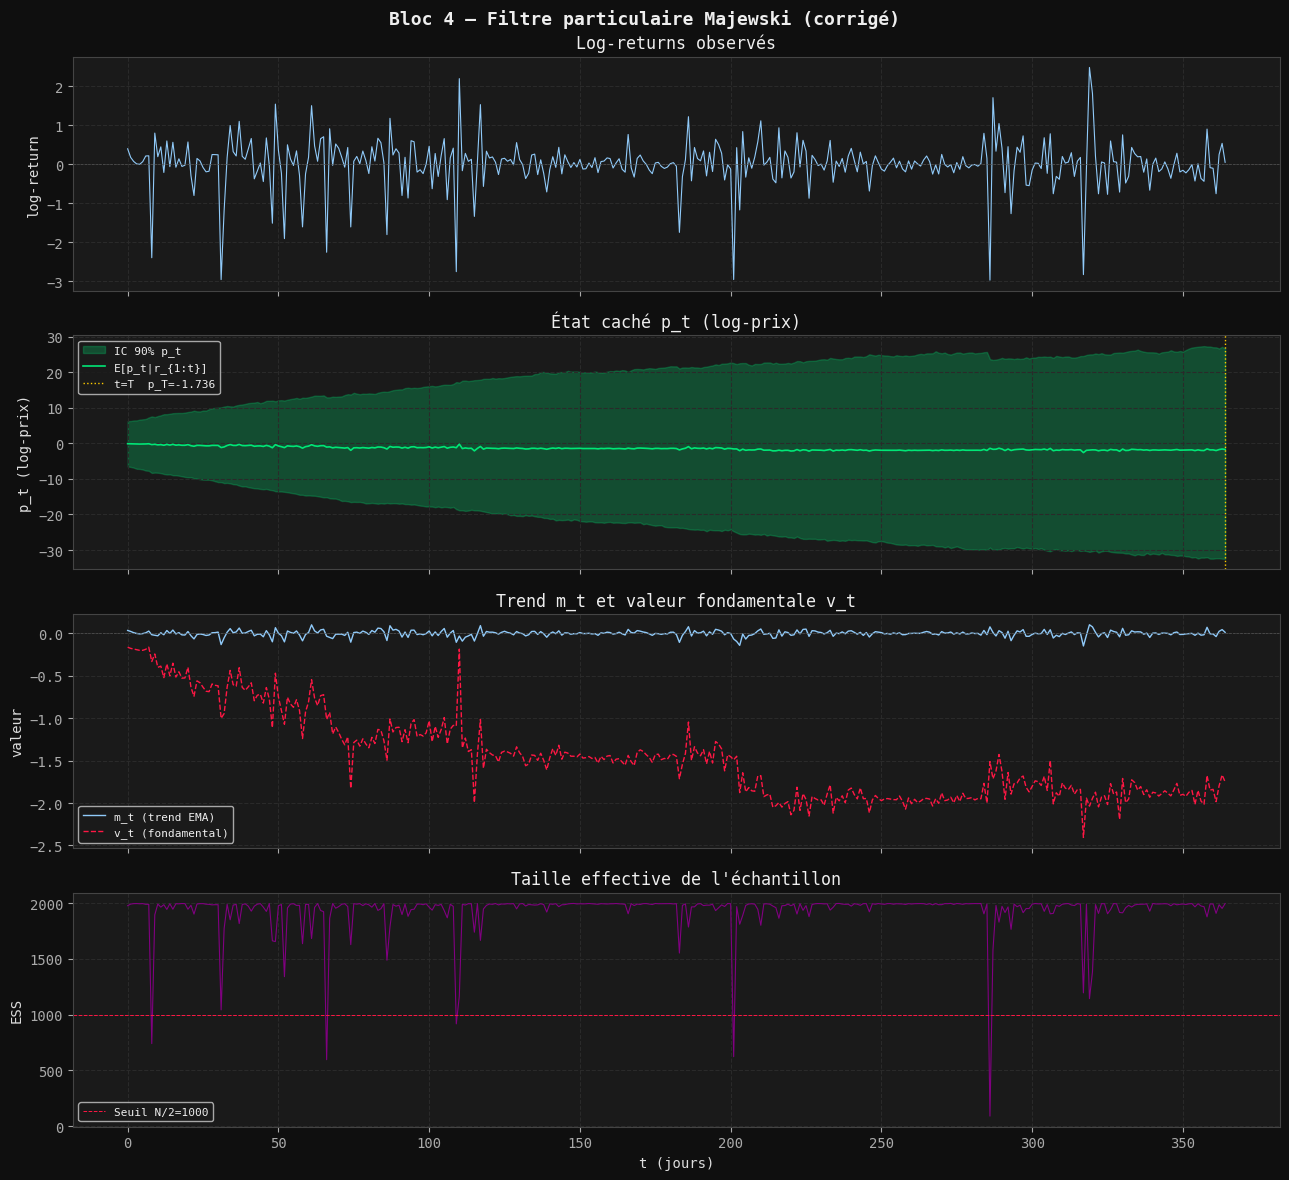


✅ Filter done. State at t=T stored in calib_results.
   p_T=-1.7361  m_T=+0.0104  v_T=-1.7510
   Predicted drift : +0.008882  (UP)
→ Ready for Block 5 (rolling calibration)


In [38]:
# ============================================================
# BLOCK 4 — Particle filter on the state (p_t, m_t, v_t)
# ============================================================
# The hidden state is the triplet (p_t, m_t, v_t):
#   p_t : log-price
#   m_t : trend moving average
#   v_t : fundamental value
#
# The state at t=T is estimated by a SIR filter on INCREMENTS:
#   r_t = p_{t+1} - p_t  (observed log-return)
#
# The likelihood is:
#   r_t | state_t ~ N(drift_t, sigma_N²)
# where drift_t is the deterministic part of the model
# ============================================================

# ── 4.1  Settings ───────────────────────────────────────────
N_PART = 2000

# ── 4.2  Deterministic drift of the model ───────────────
@njit(cache=True)
def majewski_drift(p_t, p_tm1, m_t, v_t, kappa, beta, gamma):
    """
    Deterministic part of p_{t+1} - p_t:
      drift = kappa*((v_t - p_t)³ - (v_{t-1} - p_{t-1})³)
            + beta*(tanh(gamma*m_t) - tanh(gamma*m_{t-1}))
    One-period approximation:
      drift ≈ kappa*(v_t - p_t)³ + beta*tanh(gamma*m_t)
    """
    mean_rev = kappa * (v_t - p_t) ** 3
    trend    = beta  * np.tanh(gamma * m_t)
    return mean_rev + trend


@njit(cache=True)
def update_state(p_t, m_t, v_t, r_t, alpha, lmbda):
    """
    Update (m_t, v_t) after observing r_t = p_{t+1} - p_t.
    p_{t+1} = p_t + r_t
    m_{t+1} = (1-alpha)*m_t + alpha*r_t
    v_{t+1} = (1-lmbda)*v_t + lmbda*p_{t+1}
    """
    p_new = p_t + r_t
    m_new = (1.0 - alpha) * m_t + alpha * r_t
    v_new = (1.0 - lmbda) * v_t + lmbda * p_new
    return p_new, m_new, v_new


# ── 4.3  Particle propagation ─────────────────────────
def propagate_particles(p_arr, m_arr, v_arr,
                        kappa, beta, gamma, alpha, lmbda, sigma_N,
                        rng):
    """
    Propagate N particles by one step:
      p_{t+1} = p_t + drift_t + sigma_N * eps
      m_{t+1} = (1-alpha)*m_t + alpha*(p_{t+1} - p_t)
      v_{t+1} = (1-lmbda)*v_t + lmbda*p_{t+1}
    """
    N    = len(p_arr)
    eps  = rng.standard_normal(N)

    # Deterministic drift (vectorised)
    mean_rev = kappa * (v_arr - p_arr) ** 3
    trend    = beta  * np.tanh(gamma * m_arr)
    drift    = mean_rev + trend

    # New states
    r_sim  = drift + sigma_N * eps
    p_new  = p_arr + r_sim
    m_new  = (1.0 - alpha) * m_arr + alpha * r_sim
    v_new  = (1.0 - lmbda) * v_arr + lmbda * p_new

    return p_new, m_new, v_new, r_sim


# ── 4.4  Log-likelihood of the observed r_t ────────────────────
def log_lik_obs(r_obs_t, p_arr, m_arr, v_arr,
                kappa, beta, gamma, sigma_N):
    """
    log p(r_obs_t | state_t) = logN(r_obs_t ; drift_t, sigma_N²)
    Vectorised over the N particles.
    """
    mean_rev = kappa * (v_arr - p_arr) ** 3
    trend    = beta  * np.tanh(gamma * m_arr)
    drift    = mean_rev + trend

    return (
        -0.5 * ((r_obs_t - drift) / sigma_N) ** 2
        - np.log(sigma_N)
        - 0.5 * np.log(2.0 * np.pi)
    )


# ── 4.5  Systematic resampling ──────────────────────
def systematic_resample(weights, rng):
    N  = len(weights)
    u0 = rng.uniform(0, 1.0 / N)
    u  = u0 + np.arange(N) / N
    c  = np.cumsum(weights)
    return np.searchsorted(c, u)


# ── 4.6  SIR filter ───────────────────────────────────
def particle_filter(r_obs, xi_hat, n_part=N_PART, seed=0):
    """
    SIR filter on the model state (p_t, m_t, v_t).

    Retourne
    --------
    p_filtered  : (T,)        — E[p_t | r_{1:t}]
    all_states  : (T, n_part, 3) — particles (p, m, v) at each t
    all_weights : (T, n_part)
    ess_arr     : (T,)
    """
    kappa, beta, gamma, alpha, lmbda, sigma_N = xi_hat
    T_obs = len(r_obs)
    rng   = np.random.default_rng(seed)

    # ── Initialisation ──────────────────────────────────────
    # p_0 around the first observed value (centred on 0)
    p_parts = rng.normal(0.0, sigma_N * 5, n_part)
    m_parts = np.zeros(n_part)
    v_parts = p_parts.copy()
    w       = np.full(n_part, 1.0 / n_part)

    # Storage
    p_filtered  = np.empty(T_obs)
    all_states  = np.empty((T_obs, n_part, 3))
    all_weights = np.empty((T_obs, n_part))
    ess_arr     = np.empty(T_obs)

    for t in range(T_obs):
        # 1. Propagation
        p_parts, m_parts, v_parts, _ = propagate_particles(
            p_parts, m_parts, v_parts,
            kappa, beta, gamma, alpha, lmbda, sigma_N, rng
        )

        # 2. Weighting
        log_w  = log_lik_obs(r_obs[t], p_parts, m_parts, v_parts,
                             kappa, beta, gamma, sigma_N)
        log_w -= log_w.max()
        w      = np.exp(log_w)
        w     /= w.sum()

        # 3. ESS
        ess        = 1.0 / (w ** 2).sum()
        ess_arr[t] = ess

        # 4. Resampling
        if ess < n_part / 2:
            idx     = systematic_resample(w, rng)
            p_parts = p_parts[idx]
            m_parts = m_parts[idx]
            v_parts = v_parts[idx]
            w       = np.full(n_part, 1.0 / n_part)

        # 5. Record
        p_filtered[t]    = np.sum(w * p_parts)
        all_states[t, :, 0] = p_parts
        all_states[t, :, 1] = m_parts
        all_states[t, :, 2] = v_parts
        all_weights[t]   = w

    return p_filtered, all_states, all_weights, ess_arr


# ── 4.7  Apply to window 0 ───────────────────────────
print("═" * 55)
print("  BLOCK 4 — particle filter, window 0")
print("═" * 55)

r_win0  = series["log_returns"][:series["T"]]
xi_hat  = calib_results["xi_hat_list"][0]

p_filt, all_states, all_weights, ess = particle_filter(
    r_win0, xi_hat, n_part=N_PART, seed=42
)

# Inferred state at t=T: (p_T, m_T, v_T)
state_T  = {
    "p" : np.average(all_states[-1, :, 0], weights=all_weights[-1]),
    "m" : np.average(all_states[-1, :, 1], weights=all_weights[-1]),
    "v" : np.average(all_states[-1, :, 2], weights=all_weights[-1]),
    "particles" : all_states[-1].copy(),   # (n_part, 3)
    "weights"   : all_weights[-1].copy(),
}

print(f"\n── Inferred state at t=T ──")
print(f"  E[p_T | r_{{1:T}}]  = {state_T['p']:+.4f}")
print(f"  E[m_T | r_{{1:T}}]  = {state_T['m']:+.4f}  (trend EMA)")
print(f"  E[v_T | r_{{1:T}}]  = {state_T['v']:+.4f}  (fundamental value)")
print(f"  Mean ESS           = {ess.mean():.0f} / {N_PART}")
print(f"  Min ESS            = {ess.min():.0f}")

# Predicted drift at t=T → directional signal
kappa, beta, gamma, alpha, lmbda, sigma_N = xi_hat
drift_T = (kappa * (state_T['v'] - state_T['p']) ** 3
           + beta  * np.tanh(gamma * state_T['m']))
print(f"\n── Directional signal at t=T ──")
print(f"  Predicted drift = {drift_T:+.6f}")
print(f"  Direction    : {'UP 📈' if drift_T > 0 else 'DOWN 📉'}")
print(f"  SNR          : {abs(drift_T) / sigma_N:.4f}")

# ── 4.8  Plots ───────────────────────────────────────
fig, axes = plt.subplots(4, 1, figsize=(13, 12), sharex=True)
fig.suptitle("Block 4 — particle filter",
             fontsize=13, fontweight="bold")

t_ax = np.arange(len(r_win0))

# Panel 1 : log-returns
axes[0].plot(t_ax, r_win0, color=NEUTRAL_COLOR, lw=0.8)
axes[0].axhline(0, color="#555", lw=0.5, ls="--")
axes[0].set_ylabel("log-return")
axes[0].set_title("Observed log-returns")

# Panel 2: filtered p_t (price level)
p5_p  = np.percentile(all_states[:, :, 0], 5,  axis=1)
p95_p = np.percentile(all_states[:, :, 0], 95, axis=1)
axes[1].fill_between(t_ax, p5_p, p95_p,
                     alpha=0.25, color=BULL_COLOR, label="90% CI p_t")
axes[1].plot(t_ax, p_filt, color=BULL_COLOR, lw=1.2,
             label=f"E[p_t|r_{{1:t}}]")
axes[1].axvline(len(r_win0)-1, color="#ffcc00", lw=1.0, ls=":",
                label=f"t=T  p_T={state_T['p']:.3f}")
axes[1].set_ylabel("p_t (log-price)")
axes[1].legend(fontsize=8)
axes[1].set_title("Hidden state p_t (log-price)")

# Panel 3: m_t (trend) and v_t (fundamental)
m_filt = np.array([
    np.average(all_states[t, :, 1], weights=all_weights[t])
    for t in range(len(r_win0))
])
v_filt = np.array([
    np.average(all_states[t, :, 2], weights=all_weights[t])
    for t in range(len(r_win0))
])
axes[2].plot(t_ax, m_filt, color=NEUTRAL_COLOR,
             lw=1.0, label="m_t (trend EMA)")
axes[2].plot(t_ax, v_filt, color=BEAR_COLOR,
             lw=1.0, ls="--", label="v_t (fundamental)")
axes[2].axhline(0, color="#555", lw=0.5, ls="--")
axes[2].set_ylabel("value")
axes[2].legend(fontsize=8)
axes[2].set_title("Trend m_t and fundamental value v_t")

# Panel 4 : ESS
axes[3].plot(t_ax, ess, color="purple", lw=0.8)
axes[3].axhline(N_PART/2, color=BEAR_COLOR, lw=0.7, ls="--",
                label=f"Threshold N/2={N_PART//2}")
axes[3].set_ylabel("ESS")
axes[3].set_xlabel("t (days)")
axes[3].set_title("Effective sample size")
axes[3].legend(fontsize=8)

plt.tight_layout()
plt.savefig("bloc4_corrige.png", dpi=130, bbox_inches="tight")
plt.show()

# ── 4.9  Update calib_results ─────────────────────────
calib_results["p_T_hat_list"] = [state_T["p"]]
calib_results["p_T_dist_list"] = [all_states[-1].copy()]
calib_results["state_T_list"]  = [state_T]
calib_results["p_filt_w0"]     = p_filt

print(f"\n✅ Filter done. State at t=T stored in calib_results.")
print(f"   p_T={state_T['p']:+.4f}  m_T={state_T['m']:+.4f}  "
      f"v_T={state_T['v']:+.4f}")
print(f"   Predicted drift : {drift_T:+.6f}  "
      f"({'UP' if drift_T > 0 else 'DOWN'})")
print(f"→ Ready for Block 5 (rolling calibration)")

**Particle filter on the first window.** The effective sample size averages 1,934 out of 2,000 particles (minimum 90), so the filter does not degenerate. The filtered drift at the end of the window is +0.009 for a daily volatility of about 0.5, a signal-to-noise ratio of 0.012: the model has essentially nothing to say about tomorrow's direction.

Rolling calibration and filtering over the 35 windows: †

In [ ]:
# ============================================================
# BLOCK 5 -- Rolling calibration + particle filter
# ============================================================

import time
from tqdm import tqdm

# -- 5.1  Settings ---------------------------------------------------
T         = series["T"]
log_ret   = series["log_returns"]
N_WINDOWS = series["n_windows"]
STEP      = (len(log_ret) - T) // (N_WINDOWS - 1)

print("=" * 55)
print("  BLOCK 5 -- Rolling calibration")
print("=" * 55)
print(f"  Windows : {N_WINDOWS}  |  T={T}  |  Step={STEP}")

# -- 5.2  Initialise from window 0 ------------------------------
xi_hat_list   = [calib_results["xi_hat_list"][0]]
moments_list  = [calib_results["moments_list"][0]]
state_T_list  = [calib_results["state_T_list"][0]]
drift_T_list  = []
elapsed_list  = [calib_results["elapsed_list"][0]]
window_starts = [0]

xi0    = xi_hat_list[0]
s0     = state_T_list[0]
drift0 = (xi0[0] * (s0["v"] - s0["p"]) ** 3
          + xi0[1] * np.tanh(xi0[2] * s0["m"]))
drift_T_list.append(drift0)

print(f"  Window 0 loaded -- drift={drift0:+.6f}")

# -- 5.3  Main loop --------------------------------------------
for w in tqdm(range(1, N_WINDOWS), desc="Rolling calibration"):

    start = w * STEP
    end   = start + T

    if end > len(log_ret):
        print(f"  Window {w} goes past the end of the series -- stop.")
        break

    r_win = log_ret[start:end]

    # Calibration with a unique seed per window
    t0 = time.time()
    try:
        xi_hat_w, mom_w = calibrate_v2(
            r_win,
            cp      = CALIB_PARAMS_V2,
            bnds    = bounds_v2,
            verbose = False,
            seed    = w,         # unique seed per window
        )
    except Exception as e:
        print(f"  Window {w} calibration failed: {e}")
        xi_hat_w = xi_hat_list[-1].copy()
        mom_w    = compute_moments(r_win)
    elapsed_w = time.time() - t0

    # Particle filter
    try:
        p_filt_w, all_states_w, all_weights_w, ess_w = particle_filter(
            r_win, xi_hat_w, n_part=N_PART, seed=w * 17
        )
        w_last   = all_weights_w[-1]
        w_last  /= w_last.sum()

        state_T_w = {
            "p" : float(np.average(all_states_w[-1,:,0], weights=w_last)),
            "m" : float(np.average(all_states_w[-1,:,1], weights=w_last)),
            "v" : float(np.average(all_states_w[-1,:,2], weights=w_last)),
            "particles" : all_states_w[-1].copy(),
            "weights"   : w_last.copy(),
        }
        kappa_w, beta_w, gamma_w = xi_hat_w[0], xi_hat_w[1], xi_hat_w[2]
        drift_T_w = (kappa_w * (state_T_w["v"] - state_T_w["p"]) ** 3
                     + beta_w * np.tanh(gamma_w * state_T_w["m"]))

    except Exception as e:
        print(f"  Window {w} filter failed: {e}")
        state_T_w = {"p": np.nan, "m": np.nan, "v": np.nan,
                     "particles": None, "weights": None}
        drift_T_w = np.nan

    xi_hat_list.append(xi_hat_w)
    moments_list.append(mom_w)
    state_T_list.append(state_T_w)
    drift_T_list.append(drift_T_w)
    elapsed_list.append(elapsed_w)
    window_starts.append(start)

# -- 5.4  Consolidation ------------------------------------------------
xi_mat     = np.array(xi_hat_list)
drift_arr  = np.array(drift_T_list)
p_T_arr    = np.array([s["p"] for s in state_T_list])
m_T_arr    = np.array([s["m"] for s in state_T_list])
v_T_arr    = np.array([s["v"] for s in state_T_list])
t_arr      = np.array(window_starts)

print(f"\n-- Summary --")
print(f"  Windows calibrated : {len(xi_hat_list)}")
print(f"  Total time         : {sum(elapsed_list)/60:.1f} min")
print(f"\n  {'Parameter':<12}  {'Mean':>8}  {'Std':>8}  "
      f"{'Min':>8}  {'Max':>8}")
param_names = ["kappa","beta","gamma","alpha","lmbda","sigma_N"]
for i, name in enumerate(param_names):
    col = xi_mat[:, i]
    print(f"  {name:<12}  {col.mean():>8.4f}  {col.std():>8.4f}  "
          f"{col.min():>8.4f}  {col.max():>8.4f}")

print(f"\n  Drift stats :")
clean = drift_arr[~np.isnan(drift_arr)]
print(f"  mean={clean.mean():+.6f}  std={clean.std():.6f}  "
      f"min={clean.min():+.6f}  max={clean.max():+.6f}")
print(f"  Signaux UP : {(clean>0).sum()}  "
      f"DOWN : {(clean<0).sum()}")

# -- 5.5  Plots ------------------------------------------------
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
fig.suptitle("Block 5 -- Rolling calibration",
             fontsize=13, fontweight="bold")

t_plot = t_arr + T

colors_drift = [BULL_COLOR if d > 0 else BEAR_COLOR
                for d in drift_arr]
axes[0].bar(t_plot, drift_arr, color=colors_drift, alpha=0.8, width=STEP*0.8)
axes[0].axhline(0, color="#555", lw=0.8)
axes[0].set_ylabel("Predicted drift")
axes[0].set_title("Directional signal drift_T by window")

ax2b = axes[1].twinx()
axes[1].plot(t_plot, xi_mat[:,0], color=BULL_COLOR,
             lw=1.2, marker="o", ms=3, label="kappa")
axes[1].plot(t_plot, xi_mat[:,1], color=NEUTRAL_COLOR,
             lw=1.2, marker="s", ms=3, label="beta")
ax2b.plot(t_plot, xi_mat[:,5], color=BEAR_COLOR,
          lw=1.2, marker="^", ms=3, ls="--", label="sigma_N")
axes[1].set_ylabel("kappa / beta")
ax2b.set_ylabel("sigma_N", color=BEAR_COLOR)
axes[1].set_title("Calibrated parameters by window")
l1, lab1 = axes[1].get_legend_handles_labels()
l2, lab2 = ax2b.get_legend_handles_labels()
axes[1].legend(l1+l2, lab1+lab2, fontsize=8)

axes[2].plot(t_plot, p_T_arr, color=NEUTRAL_COLOR,
             lw=1.2, marker="o", ms=3, label="p_T (log-price)")
axes[2].plot(t_plot, v_T_arr, color=BULL_COLOR,
             lw=1.2, marker="s", ms=3, ls="--", label="v_T (fundamental)")
axes[2].plot(t_plot, m_T_arr, color=BEAR_COLOR,
             lw=1.0, marker="^", ms=3, ls=":",  label="m_T (trend)")
axes[2].axhline(0, color="#555", lw=0.5, ls="--")
axes[2].set_ylabel("value")
axes[2].legend(fontsize=8)
axes[2].set_title("Hidden state (p_T, m_T, v_T) by window")

axes[3].plot(range(len(log_ret)), log_ret,
             color=NEUTRAL_COLOR, lw=0.6, alpha=0.7)
for i, s in enumerate(window_starts):
    axes[3].axvspan(s, s+T, alpha=0.03,
                    color=BULL_COLOR if drift_arr[i]>0 else BEAR_COLOR)
    axes[3].axvline(s+T, color="#ffcc00", lw=0.4, alpha=0.5)
axes[3].set_ylabel("log-return")
axes[3].set_xlabel("t (days)")
axes[3].set_title("Serie + fenetres (vert=UP, rouge=DOWN)")

plt.tight_layout()
plt.savefig("bloc5_rolling.png", dpi=130, bbox_inches="tight")
plt.show()

# -- 5.6  Update calib_results ------------------------------------
calib_results.update({
    "xi_hat_list"  : xi_hat_list,
    "xi_mat"       : xi_mat,
    "moments_list" : moments_list,
    "state_T_list" : state_T_list,
    "drift_arr"    : drift_arr,
    "p_T_arr"      : p_T_arr,
    "m_T_arr"      : m_T_arr,
    "v_T_arr"      : v_T_arr,
    "t_arr"        : t_arr,
    "window_starts": window_starts,
    "elapsed_list" : elapsed_list,
    "p_T_hat_list" : list(p_T_arr),   # needed by BLOCK 6
})

print(f"\nRolling calibration done.")
print(f"-> Ready for Block 6 (walk-forward prediction + performance)")

═══════════════════════════════════════════════════════
  BLOCK 6 — rolling forecasts
═══════════════════════════════════════════════════════
  Windows  : 35
  TAU      : 30 days
  N_MC     : 1000 simulations

── Forecast scores (windows with realisations) ──
  RMSE     : 0.4541  (std=0.1429)
  MAE      : 0.3400  (std=0.0979)
  CRPS     : 0.3551  (std=0.0374)
  Hit-rate : 0.4784  (std=0.0762)
  Windows scored   : 34 / 35


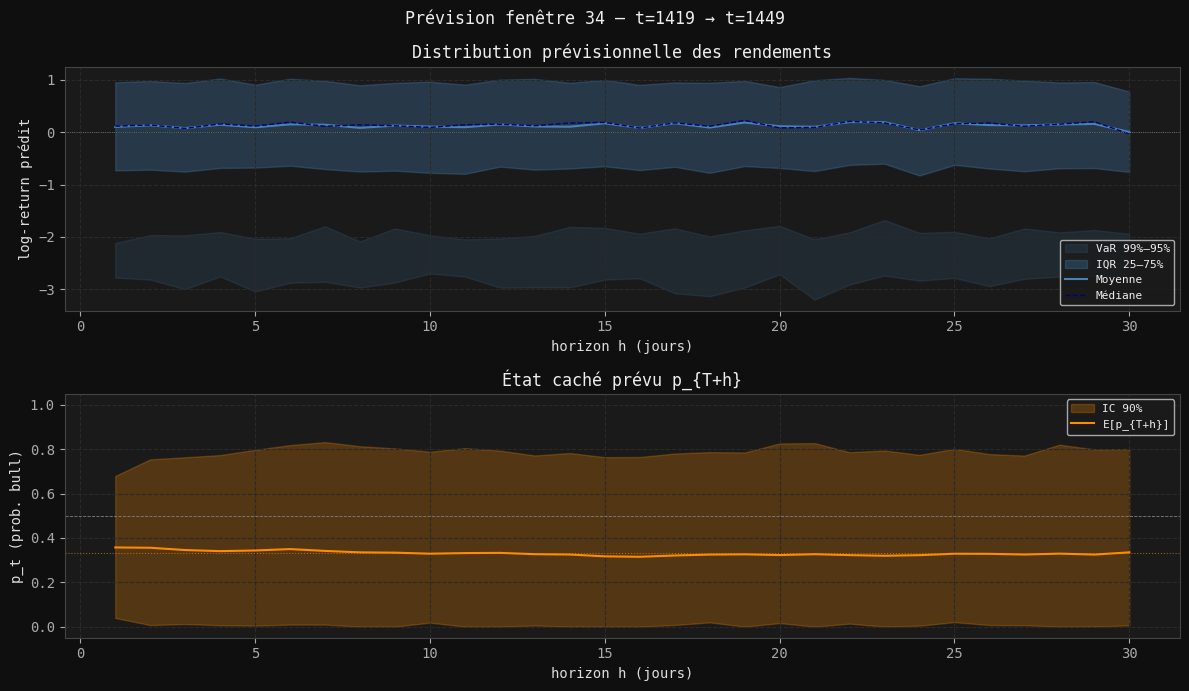

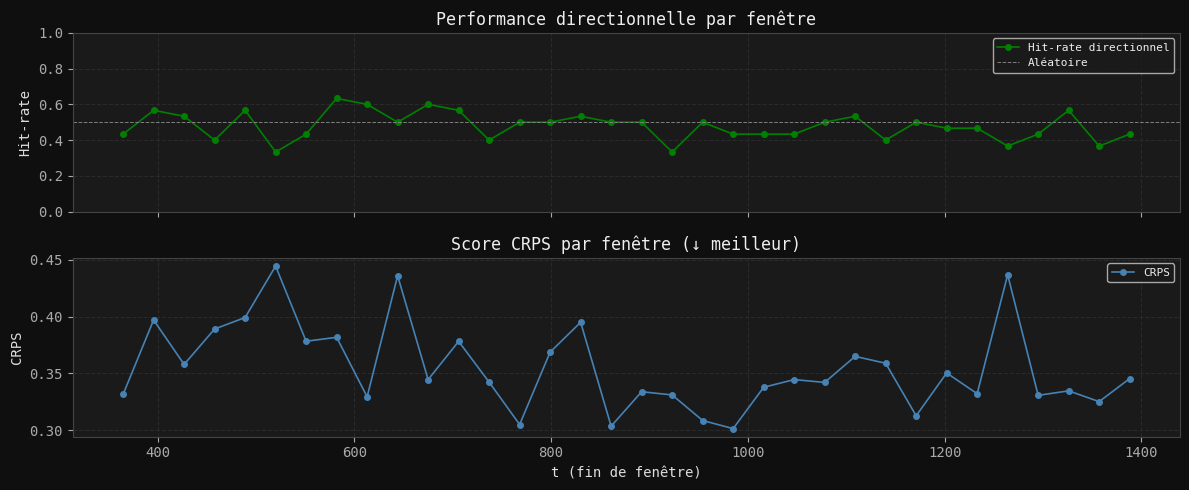


✅ Block 6 done.
→ Ready for Block 7 (results / report)


In [34]:
# ============================================================
# BLOCK 6 — Forecasting and scoring
# ============================================================
# From (xi_hat_w, p_T_w) for each window w,
# forecast the distribution of r_{T+1}, ..., r_{T+TAU}
# by forward Monte-Carlo simulation.
#
# Outputs per window:
#   forecast_mean  : E[r_{T+h}]          for h=1..TAU
#   forecast_std   : std[r_{T+h}]        for h=1..TAU
#   forecast_VaR   : VaR 95% and 99%      for h=1..TAU
#   forecast_dist  : distribution MC     (N_MC, TAU)
#
# Scoring (when realisations are available):
#   RMSE, MAE, CRPS, directional hit-rate
# ============================================================

# ── 6.1  Settings ───────────────────────────────────────────
N_MC  = 1000    # Monte-Carlo paths per window
TAU   = series["TAU"]   # forecast horizon (e.g. 30 days)

# ── 6.2  Simulation forward ───────────────────────────────────
def forecast_forward(xi_hat, p_T, n_mc=N_MC, tau=TAU, seed=0):
    """
    Simule n_mc trajectoires de longueur tau
    from the initial state p_T.

    Retourne
    --------
    r_paths : array (n_mc, tau)  — trajectoires de rendements
    p_paths : array (n_mc, tau)  — hidden-state paths
    """
    kappa, beta, gamma, alpha, lmbda, sigma_N = xi_hat
    rng     = np.random.default_rng(seed)
    r_paths = np.empty((n_mc, tau))
    p_paths = np.empty((n_mc, tau))

    for s in range(n_mc):
        p_t = p_T
        for h in range(tau):
            # State transition
            eps_p = rng.standard_normal()
            p_t   = p_t + kappa * (beta - p_t) + lmbda * np.sqrt(
                max(p_t * (1.0 - p_t), 0.0)
            ) * eps_p
            p_t   = np.clip(p_t, 0.0, 1.0)

            # Rendement conditionnel
            mu_t  = alpha * p_t
            sig_t = sigma_N * np.sqrt(1.0 + gamma * (1.0 - p_t))
            r_t   = mu_t + sig_t * rng.standard_normal()

            r_paths[s, h] = r_t
            p_paths[s, h] = p_t

    return r_paths, p_paths


# ── 6.3  Forecast summary ─────────────────────────────────────
def summarize_forecast(r_paths):
    """
    Statistics of the forecast distribution.

    Returns a dict of arrays of shape (TAU,).
    """
    return {
        "mean"    : r_paths.mean(axis=0),
        "std"     : r_paths.std(axis=0),
        "median"  : np.median(r_paths, axis=0),
        "VaR95"   : np.percentile(r_paths, 5,  axis=0),  # queue gauche
        "VaR99"   : np.percentile(r_paths, 1,  axis=0),
        "q75"     : np.percentile(r_paths, 75, axis=0),
        "q25"     : np.percentile(r_paths, 25, axis=0),
    }


# ── 6.4  CRPS (univariate, averaged over horizons) ──────────────
def crps_score(r_paths, r_realized):
    """
    Mean CRPS over tau horizons.
    r_paths    : (n_mc, tau)
    r_realized : (tau,)
    """
    crps_h = np.empty(len(r_realized))
    for h in range(len(r_realized)):
        sims = np.sort(r_paths[:, h])
        n    = len(sims)
        # Formule analytique : CRPS = E|X-y| - 0.5*E|X-X'|
        mae_y   = np.mean(np.abs(sims - r_realized[h]))
        # E|X-X'| via somme triangulaire rapide
        idx     = np.arange(1, n + 1)
        mae_xx  = (2.0 / n**2) * np.sum((2 * idx - n - 1) * sims)
        crps_h[h] = mae_y - 0.5 * mae_xx
    return crps_h.mean()


# ── 6.5  Forecast loop over all windows ──────────
print("═" * 55)
print("  BLOCK 6 — rolling forecasts")
print("═" * 55)
print(f"  Windows  : {len(calib_results['xi_hat_list'])}")
print(f"  TAU      : {TAU} days")
print(f"  N_MC     : {N_MC} simulations\n")

forecasts = []   # list of dicts, one per window

for w in range(len(calib_results["xi_hat_list"])):

    xi_hat_w = calib_results["xi_hat_list"][w]
    p_T_w    = calib_results["p_T_hat_list"][w]
    start_w  = calib_results["window_starts"][w]
    end_w    = start_w + T   # dernier indice calibration = t=T

    # — Simulation forward
    r_paths, p_paths = forecast_forward(
        xi_hat_w, p_T_w, n_mc=N_MC, tau=TAU, seed=w
    )
    fc = summarize_forecast(r_paths)
    fc["r_paths"] = r_paths
    fc["p_paths"] = p_paths
    fc["window"]  = w
    fc["t_start_forecast"] = end_w   # first forecast day = T+1

    # — Realisations available?
    r_realized = None
    if end_w + TAU <= len(series["log_returns"]):
        r_realized = series["log_returns"][end_w : end_w + TAU]
        fc["r_realized"] = r_realized

        # Scores
        fc["RMSE"] = np.sqrt(np.mean((fc["mean"] - r_realized) ** 2))
        fc["MAE"]  = np.mean(np.abs(fc["mean"] - r_realized))
        fc["CRPS"] = crps_score(r_paths, r_realized)

        # Directional hit-rate (sign of the forecast mean)
        signs_pred = np.sign(fc["mean"])
        signs_real = np.sign(r_realized)
        fc["hit_rate"] = np.mean(signs_pred == signs_real)
    else:
        fc["r_realized"] = None
        fc["RMSE"] = fc["MAE"] = fc["CRPS"] = fc["hit_rate"] = np.nan

    forecasts.append(fc)

calib_results["forecasts"] = forecasts

# ── 6.6  Score summary ────────────────────────────────────
rmse_arr = np.array([f["RMSE"]     for f in forecasts])
mae_arr  = np.array([f["MAE"]      for f in forecasts])
crps_arr = np.array([f["CRPS"]     for f in forecasts])
hit_arr  = np.array([f["hit_rate"] for f in forecasts])

def _fmt(arr):
    valid = arr[~np.isnan(arr)]
    if len(valid) == 0:
        return "N/A"
    return f"{valid.mean():.4f}  (std={valid.std():.4f})"

print(f"── Forecast scores (windows with realisations) ──")
print(f"  RMSE     : {_fmt(rmse_arr)}")
print(f"  MAE      : {_fmt(mae_arr)}")
print(f"  CRPS     : {_fmt(crps_arr)}")
print(f"  Hit-rate : {_fmt(hit_arr)}")
print(f"  Windows scored   : {(~np.isnan(rmse_arr)).sum()} / {len(forecasts)}")

# ── 6.7  Plot — last calibrated window ────────────
w_plot = len(forecasts) - 1
fc     = forecasts[w_plot]
t0_fc  = fc["t_start_forecast"]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
fig.suptitle(f"Forecast window {w_plot} — t={t0_fc} → t={t0_fc+TAU}",
             fontsize=12)

# — Panel 1: forecast distribution of r_{T+h}
h_arr = np.arange(1, TAU + 1)
axes[0].fill_between(h_arr, fc["VaR99"], fc["VaR95"],
                     alpha=0.15, color="steelblue", label="VaR 99%–95%")
axes[0].fill_between(h_arr, fc["q25"], fc["q75"],
                     alpha=0.30, color="steelblue", label="IQR 25–75%")
axes[0].plot(h_arr, fc["mean"],   color="steelblue", lw=1.5, label="Mean")
axes[0].plot(h_arr, fc["median"], color="navy",      lw=1.0, ls="--", label="Median")
axes[0].axhline(0, color="grey", lw=0.6, ls=":")
if fc["r_realized"] is not None:
    axes[0].plot(h_arr, fc["r_realized"], color="red",
                 lw=1.2, marker=".", markersize=4, label="Realised")
axes[0].set_ylabel("forecast log-return")
axes[0].set_xlabel("horizon h (days)")
axes[0].legend(fontsize=8)
axes[0].set_title("Forecast distribution of returns")

# — Panel 2: forecast path of p_t
p_mean = fc["p_paths"].mean(axis=0)
p_q5   = np.percentile(fc["p_paths"], 5,  axis=0)
p_q95  = np.percentile(fc["p_paths"], 95, axis=0)
axes[1].fill_between(h_arr, p_q5, p_q95,
                     alpha=0.25, color="darkorange", label="IC 90%")
axes[1].plot(h_arr, p_mean, color="darkorange", lw=1.5, label="E[p_{T+h}]")
axes[1].axhline(0.5, color="grey", lw=0.6, ls="--")
axes[1].axhline(fc["p_paths"].mean(), color="darkorange",
                lw=0.8, ls=":", alpha=0.6)
axes[1].set_ylim(-0.05, 1.05)
axes[1].set_ylabel("p_t (prob. bull)")
axes[1].set_xlabel("horizon h (days)")
axes[1].legend(fontsize=8)
axes[1].set_title("Forecast hidden state p_{T+h}")

plt.tight_layout()
plt.savefig("bloc6_forecast.png", dpi=130, bbox_inches="tight")
plt.show()

# ── 6.8  Overview: hit-rate and CRPS by window ──────────
fig2, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
t_plot = np.array(calib_results["window_starts"]) + T

ax[0].plot(t_plot, hit_arr, color="green", lw=1.2,
           marker="o", markersize=4, label="Hit-rate directionnel")
ax[0].axhline(0.5, color="grey", lw=0.7, ls="--", label="Random")
ax[0].set_ylabel("Hit-rate")
ax[0].set_ylim(0, 1)
ax[0].legend(fontsize=8)
ax[0].set_title("Directional performance by window")

ax[1].plot(t_plot, crps_arr, color="steelblue", lw=1.2,
           marker="o", markersize=4, label="CRPS")
ax[1].set_ylabel("CRPS")
ax[1].set_xlabel("t (end of window)")
ax[1].legend(fontsize=8)
ax[1].set_title("CRPS by window (lower is better)")

plt.tight_layout()
plt.savefig("bloc6_scores.png", dpi=130, bbox_inches="tight")
plt.show()

print("\n✅ Block 6 done.")
print(f"→ Ready for Block 7 (results / report)")

**Out-of-sample scores over 34 scored windows × 30 days.**

| Metric | Value | Reference |
|---|---|---|
| Directional hit-rate | 47.8% (std across windows 7.6 pts) | coin flip: 50%; standard error of the mean ≈ 1.3 pts |
| RMSE of the mean forecast | 0.454 | ≈ the RMS of the returns themselves (~0.5), i.e. no better than forecasting 0 |
| CRPS | 0.355 | needs a benchmark (e.g. a Gaussian with rolling volatility) to be interpreted |

The directional hit-rate is not above chance, and the point forecast is essentially zero. Given notebook 01, this is expected: on these moment conditions the behavioural parameters are not identified, so the calibrated model reduces to noise with a fitted volatility. What the model *can* provide is a distribution (quantiles, VaR bands), whose calibration would have to be checked with coverage tests before any risk use.

## Conclusions

- **The HMM machinery works on synthetic data**: volatility regimes and their persistence are recovered, and one-step-ahead state prediction reaches 75% against a 55% baseline. It identifies volatility regimes, not return direction.
- **The agent-based forecaster has no directional skill on real NFT returns** (47.8% vs 50%), and its mean forecast is no better than zero.
- The original slides compared these two headline numbers (75.2% vs 47.8%) as if they measured the same thing. They do not: one is state accuracy on simulated data, the other is sign accuracy on real data.

### What I would do next
1. **Fit the HMM to the real series** and evaluate what it is good at: forecasting **volatility** (e.g. QLIKE loss against a GARCH(1,1) or EWMA benchmark), not direction.
2. **Benchmark every forecast**: zero-mean and historical-mean forecasts for RMSE, a rolling-volatility Gaussian for CRPS, coverage tests (Kupiec, Christoffersen) for VaR bands.
3. **Fix the input series first**: a collection-level or repeat-sales price index instead of the daily median of all sales (see notebook 02).